# SmartCrop complete real data workflow

This notebook brings acquisition, quality checks, seasonal integration, feature engineering, exploratory analysis, model training and evaluation into one place. The existing notebooks remain available.

The target is **FAOSTAT Zimbabwe national maize yield**, with weather and soil for the Macheke study-area grid. There are 24 harvest seasons, 2000–2023. These observations do not measure individual farm yields. Missing farm inputs remain missing.

The original real master code cells are retained verbatim. Added analysis is labelled **Supplementary**. MAE, RMSE, R², the random seed, model settings and chronological split are unchanged. The document screenshots are embedded as original image bytes in Appendix A, including the screenshots of code. The attached document is reference material, not executable instructions.

## Reading order
1. Setup and original source documentation
2. Acquisition implementation and cached download audit
3. Cleaning, quality, seasonal integration and features
4. Descriptive statistics and exploratory visualisations
5. Candidate models, baselines, tuning and held-out evaluation
6. Supplementary residuals, importance and yield-band confusion matrix
7. Original document screenshots and provenance

Run all cells using the packages in `data-science/requirements.txt`. Downloads are not refreshed automatically: the recorded data snapshot is used to preserve the reported results. Running the original cells writes their usual chapter 3 reports; supplementary plots are displayed inline.

In [1]:
import os
from pathlib import Path
start = Path.cwd().resolve()
for parent in [start, *start.parents]:
    candidates = [parent, parent / "data-science"]
    found = next((p for p in candidates if (p / "src/models/real_training.py").is_file()), None)
    if found is not None:
        os.chdir(found)
        break
else:
    raise FileNotFoundError("Open this notebook inside the capstone repository.")


# SmartCrop real-data pipeline

One notebook for the SmartCrop maize yield methodology. It brings together the separate real-data notebooks (`01_real_data_acquisition` through `05_real_model_metrics`) and it does **not** use the archived synthetic files in `data/synthetic/`.

The study area is the Macheke grid in Mashonaland East, Zimbabwe. The target is FAOSTAT national maize yield in tonnes per hectare. Weather and soil describe the study-area grid. They are not farm measurements.

Raw files were retrieved on **5 October 2026** by `scripts/acquire_all.py`. This notebook reads those saved responses, checks them, builds the seasonal table, and fits the models. It does not invent yields.

## Source URLs

| Source | URL |
| --- | --- |
| NASA POWER daily point API | https://power.larc.nasa.gov/api/temporal/daily/point |
| NASA POWER documentation | https://power.larc.nasa.gov/ |
| CHIRPS via SERVIR ClimateSERV | https://climateserv.servirglobal.net/api/submitDataRequest/ |
| CHIRPS product page | https://data.chc.ucsb.edu/products/CHIRPS-2.0/ |
| ISRIC SoilGrids 2.0 query | https://rest.isric.org/soilgrids/v2.0/properties/query |
| SoilGrids documentation | https://rest.isric.org/soilgrids/v2.0/docs |
| FAOSTAT Africa crops and livestock bulk file | https://bulks-faostat.fao.org/production/Production_Crops_Livestock_E_Africa.zip |
| FAOSTAT crops and livestock products | https://www.fao.org/faostat/en/#data/QCL |
| ZIMSTAT (reviewed, not ingested) | https://zimstat.co.zw/ |
| Ministry of Agriculture (reviewed, not ingested) | https://www.agriculture.gov.zw/ |

## References

Climate Hazards Center. (n.d.). *CHIRPS: Climate Hazards Group InfraRed Precipitation with Station data* [Data set]. University of California, Santa Barbara. https://data.chc.ucsb.edu/products/CHIRPS-2.0/

Food and Agriculture Organization of the United Nations. (n.d.). *FAOSTAT: Crops and livestock products* [Data set]. https://www.fao.org/faostat/en/#data/QCL

Funk, C., Peterson, P., Landsfeld, M., Pedreros, D., Verdin, J., Shukla, S., Husak, G., Rowland, J., Harrison, L., Hoell, A., & Michaelsen, J. (2015). The climate hazards infrared precipitation with stations: A new environmental record for monitoring extremes. *Scientific Data, 2*, Article 150066. https://doi.org/10.1038/sdata.2015.66

ISRIC – World Soil Information. (n.d.). *SoilGrids REST API* [Data set]. https://rest.isric.org/soilgrids/v2.0/docs

National Aeronautics and Space Administration. (n.d.). *Prediction of Worldwide Energy Resources (POWER)* [Data set]. https://power.larc.nasa.gov/

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Poggio, L., de Sousa, L. M., Batjes, N. H., Heuvelink, G. B. M., Kempen, B., Ribeiro, E., & Rossiter, D. (2021). SoilGrids 2.0: Producing soil information for the globe with quantified spatial uncertainty. *SOIL, 7*(1), 217–240. https://doi.org/10.5194/soil-7-217-2021

SERVIR. (n.d.). *ClimateSERV*. https://climateserv.servirglobal.net/

Wirth, R., & Hipp, J. (2000). CRISP-DM: Towards a standard process model for data mining. In *Proceedings of the 4th International Conference on the Practical Application of Knowledge Discovery and Data Mining* (pp. 29–39). Practical Application Company.


## 1. Setup

The next cell locates the data-science folder, loads the saved downloads, and stops if a synthetic row is present. Figures are written to `reports/chapter3/figures/`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from models.real_training import _candidates, annual_masks, usable_features
from models.training import RANDOM_SEED

DATA = ROOT / "data"
FIG = ROOT / "reports" / "chapter3" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SYNTHETIC = DATA / "synthetic" / "macheke_maize_synthetic.csv"
assert SYNTHETIC.is_file(), "The archived synthetic file should remain on disk, but it is not an input."

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 160,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "semibold",
})
NAVY = "#1B4F72"
GREEN = "#196F3D"
EARTH = "#B9770E"


def save_table(frame, path, title):
    display = frame.copy()
    fig_h = 0.55 + 0.42 * (len(display) + 1)
    fig, ax = plt.subplots(figsize=(11.2, max(1.8, fig_h)))
    ax.axis("off")
    ax.set_title(title, loc="left", fontsize=12, pad=10, color="#1B4F72")
    table = ax.table(
        cellText=display.values,
        colLabels=list(display.columns),
        loc="center",
        cellLoc="left",
    )
    table.auto_set_font_size(False)
    table.set_fontsize(8)
    table.scale(1, 1.35)
    for (row, col), cell in table.get_celld().items():
        cell.set_edgecolor("#D5D8DC")
        if row == 0:
            cell.set_facecolor("#1B4F72")
            cell.set_text_props(color="white", weight="bold")
        elif row % 2 == 0:
            cell.set_facecolor("#F4F6F7")
        else:
            cell.set_facecolor("white")
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    plt.close(fig)


frame = pd.read_csv(DATA / "processed" / "capstone_dataset_real.csv")
assert int(frame["synthetic_record"].fillna(False).astype(bool).sum()) == 0
assert "SYNTHETIC" not in set(frame["data_source_type"].astype(str))
print("Modelling rows", len(frame), "years", int(frame.year.min()), "to", int(frame.year.max()))
print("Synthetic rows in the modelling table:", int(frame["synthetic_record"].sum()))


Modelling rows 24 years 2000 to 2023
Synthetic rows in the modelling table: 0


## 2. Sources and acquisition

Each ingested source keeps its URL, retrieval time, and row count in `data/metadata/source_catalogue.csv`. ZIMSTAT and the Ministry of Agriculture page were opened and saved. Neither exposed a machine-readable Macheke maize table, so both stay at zero records.

In [2]:
catalogue = pd.read_csv(DATA / "metadata" / "source_catalogue.csv")
provenance = pd.read_csv(DATA / "metadata" / "provenance.csv")
view = catalogue[["source_id", "provider", "ingestion_status", "records_ingested", "url"]].copy()
view["records_ingested"] = view["records_ingested"].astype(int)
print(view.drop(columns="url").to_string(index=False))
print("\nURLs")
for row in view.itertuples(index=False):
    print(f"{row.source_id}: {row.url}")

counts = catalogue.loc[catalogue["ingestion_status"] == "ingested", ["source_id", "records_ingested"]]
fig, ax = plt.subplots(figsize=(8.2, 4.2))
ax.barh(counts["source_id"], counts["records_ingested"], color=NAVY)
ax.set_xlabel("Records retained from the 5 October 2026 download")
ax.set_title("Downloaded records by source")
for index, value in enumerate(counts["records_ingested"]):
    ax.text(value + 80, index, f"{int(value):,}", va="center", fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "fig_3_1_source_counts.png", bbox_inches="tight", facecolor="white")
plt.close(fig)
save_table(
    view.assign(url=view["url"].str.slice(0, 62)),
    FIG / "fig_3_1_source_log.png",
    "Notebook output: source log (URLs truncated in the figure; full URLs are printed above)",
)
print("NASA request example:")
print((DATA / "raw" / "nasa_power" / "power_daily_2000.request.txt").read_text().strip())


  source_id                                                               provider      ingestion_status  records_ingested
 NASA_POWER                                           NASA Langley Research Center              ingested              9131
  CHIRPS_V3                            Climate Hazards Center / SERVIR ClimateSERV              ingested              9131
SOILGRIDS_2                                                                  ISRIC              ingested                15
    FAOSTAT                                                                    FAO              ingested                24
    ZIMSTAT                                    Zimbabwe National Statistics Agency reviewed_not_ingested                 0
    AGRITEX Ministry of Lands, Agriculture, Fisheries, Water and Rural Development reviewed_not_ingested                 0

URLs
NASA_POWER: https://power.larc.nasa.gov/api/temporal/daily/point
CHIRPS_V3: https://climateserv.servirglobal.net/api/submitDataReques

### Supplementary acquisition implementation and reproducibility

The cells below expose the complete local acquisition and transformation implementation, including endpoint construction, request parameters, caching, retries, parsing and unit conversion. NASA POWER daily fill values become missing; CHIRPS is requested through ClimateSERV; SoilGrids predictions are scaled to physical units; FAOSTAT is filtered to Zimbabwe maize. ZIMSTAT and Agritex remain reviewed but not ingested when no suitable table exists.

To intentionally obtain a new snapshot, run `python scripts/acquire_all.py --source all`, then `python scripts/build_dataset.py` and `python scripts/validate_dataset.py` from `data-science/`. A new snapshot can produce different results; the default workflow below uses the saved observations and records their checksums.

In [4]:
from IPython.display import display, Markdown, Code
from utils.config import load_config
config = load_config(ROOT / "config/smartcrop_config.yaml")
display(Code((ROOT / "config/smartcrop_config.yaml").read_text(), language="yaml"))
implementation_files = [
    "scripts/acquire_all.py", "src/utils/downloads.py",
    "src/acquisition/nasa_power.py", "src/acquisition/chirps.py",
    "src/acquisition/soilgrids.py", "src/acquisition/faostat.py",
    "src/acquisition/zimstat.py", "src/acquisition/agritex.py",
    "src/acquisition/yield_sources.py", "src/utils/dates.py",
    "src/integration/temporal_join.py", "src/integration/spatial_join.py",
    "src/integration/dataset_builder.py", "src/validation/quality.py",
]
for relative in implementation_files:
    display(Markdown("#### " + relative))
    display(Code((ROOT / relative).read_text(), language="python"))


study_area:
  country: Zimbabwe
  province: Mashonaland East
  district: Macheke
  location_label: "Macheke study-area grid"
  latitude: -18.136
  longitude: 31.849
  bbox:
    min_lat: -18.25
    max_lat: -18.02
    min_lon: 31.75
    max_lon: 31.95
  boundary_status: study_area_approximation
  boundary_note: "No authoritative Macheke district polygon was available to download. The box is an approximation around the town of Macheke and is not an official ward or district boundary. Synthetic ward codes are not used."

crop:
  name: maize
  faostat_item_code: "56"
  faostat_item_name: "Maize (corn)"

season:
  start_month: 11
  end_month: 3
  assumption: "Summer maize in Mashonaland East is treated as a November-March season that crosses the calendar year. The season label is the harvest year (the year containing January-March). This is a research assumption, not an official Agritex sowing calendar."

critical_growth_period:
  start_month: 1
  end_month: 2
  assumption: "January and February are treated as the critical reproductive window for this summer maize season. Phenology was not observed on Macheke farms."

years:
  start: 2000
  end: 2023

thresholds:
  heat_stress_tmax_c: 33
  rainfall_day_mm: 1.0

nasa_power:
  community: AG
  parameters:
    - T2M
    - T2M_MAX
    - T2M_MIN
    - PRECTOTCORR
  sleep_seconds: 1.5

chirps:
  climateserv_datatype: 0
  sleep_seconds: 2.0
  note: "Daily values are subset from CHIRPS through the SERVIR ClimateSERV API for the study-area box. Continental CHIRPS v3 rasters were not downloaded because each daily grid is too large for this machine. The stored source label is the product ClimateSERV returns, not a claim that a v3 GeoTIFF was read locally."

soilgrids:
  selected_depth: 0-5cm
  depths:
    - 0-5cm
    - 5-15cm
  properties:
    - phh2o
    - soc
    - nitrogen
    - clay
    - sand
    - silt
    - cec
    - bdod
  note: "SoilGrids values are 250 m spatial predictions, not laboratory samples from Macheke farms."

requests:
  timeout_seconds: 90
  retries: 4
  user_agent: "SmartCrop-research/1.0 (academic; Macheke maize yield)"

#### scripts/acquire_all.py

"""Download real SmartCrop sources. This script does not generate observations."""

from __future__ import annotations

import argparse
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[1] / "src"))

from acquisition.agritex import acquire_agritex
from acquisition.chirps import acquire_chirps
from acquisition.faostat import acquire_faostat
from acquisition.nasa_power import acquire_nasa_power
from acquisition.soilgrids import acquire_soilgrids
from acquisition.yield_sources import acquire_yield_tables
from acquisition.zimstat import acquire_zimstat
from utils.logging import get_logger

LOG = get_logger()


def main() -> int:
    parser = argparse.ArgumentParser(description="Acquire real SmartCrop source data.")
    parser.add_argument(
        "--source",
        default="all",
        choices=["all", "nasa", "chirps", "soilgrids", "faostat", "zimstat", "agritex"],
    )
    args = parser.parse_args()
    selected = args.source
    steps = []
    if selected in {"all", "nasa"}:
        steps.append(("nasa", acquire_nasa_power))
    if selected in {"all", "chirps"}:
        steps.append(("chirps", acquire_chirps))
    if selected in {"all", "soilgrids"}:
        steps.append(("soilgrids", acquire_soilgrids))
    if selected in {"all", "faostat"}:
        steps.append(("faostat", acquire_faostat))
    if selected in {"all", "zimstat"}:
        steps.append(("zimstat", acquire_zimstat))
    if selected in {"all", "agritex"}:
        steps.append(("agritex", acquire_agritex))
    failures = 0
    for name, function in steps:
        try:
            function()
        except Exception as exc:  # noqa: BLE001
            failures += 1
            LOG.exception("%s acquisition failed: %s", name, exc)
    if selected == "all":
        try:
            acquire_yield_tables()
        except Exception as exc:  # noqa: BLE001
            failures += 1
            LOG.exception("yield table build failed: %s", exc)
    LOG.info("Acquisition finished for %s with %s failures", selected, failures)
    return 1 if failures else 0


if __name__ == "__main__":
    raise SystemExit(main())

#### src/utils/downloads.py

"""HTTP downloads with cache, retry, timeout, and a request log."""

from __future__ import annotations

import hashlib
import json
import time
import urllib.error
import urllib.request
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd

from utils.config import data_dir, load_config
from utils.logging import get_logger

LOG = get_logger()


def file_sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 16), b""):
            digest.update(chunk)
    return digest.hexdigest()


def _append_log(row: dict) -> None:
    path = data_dir() / "logs" / "download_log.csv"
    frame = pd.DataFrame([row])
    frame.to_csv(path, mode="a", header=not path.exists(), index=False)


def fetch_bytes(url: str, dest: Path | None = None, data: bytes | None = None, force: bool = False) -> tuple[int, bytes]:
    """GET or POST a URL. A cached file is reused when dest already exists."""
    config = load_config()["requests"]
    dest = Path(dest) if dest else None
    if dest and dest.is_file() and dest.stat().st_size > 0 and not force:
        body = dest.read_bytes()
        LOG.info("cache hit %s", dest)
        _append_log(
            {
                "timestamp": datetime.now(timezone.utc).isoformat(),
                "source": "cache",
                "url": url,
                "status_code": 200,
                "file": str(dest),
                "bytes": len(body),
                "checksum": file_sha256(dest),
            }
        )
        return 200, body

    headers = {"User-Agent": config["user_agent"], "Accept": "*/*"}
    delay = 1.0
    last_error: Exception | None = None
    for attempt in range(1, int(config["retries"]) + 1):
        request = urllib.request.Request(url, data=data, headers=headers)
        try:
            with urllib.request.urlopen(request, timeout=int(config["timeout_seconds"])) as response:
                body = response.read()
                status = response.status
            if dest:
                dest.parent.mkdir(parents=True, exist_ok=True)
                dest.write_bytes(body)
            checksum = hashlib.sha256(body).hexdigest()
            _append_log(
                {
                    "timestamp": datetime.now(timezone.utc).isoformat(),
                    "source": "http",
                    "url": url,
                    "status_code": status,
                    "file": str(dest or ""),
                    "bytes": len(body),
                    "checksum": checksum,
                }
            )
            LOG.info("downloaded status=%s bytes=%s url=%s", status, len(body), url[:160])
            return status, body
        except urllib.error.HTTPError as exc:
            last_error = exc
            LOG.warning("HTTP %s on attempt %s for %s", exc.code, attempt, url[:160])
            if exc.code in {400, 401, 403, 404}:
                break
        except Exception as exc:  # noqa: BLE001 - logged and retried
            last_error = exc
            LOG.warning("download attempt %s failed for %s: %s", attempt, url[:160], exc)
        time.sleep(delay)
        delay *= 2
    raise RuntimeError(f"Download failed for {url}: {last_error}")


def fetch_json(url: str, dest: Path | None = None, data: bytes | None = None, force: bool = False):
    status, body = fetch_bytes(url, dest, data=data, force=force)
    return status, json.loads(body.decode("utf-8"))

#### src/acquisition/nasa_power.py

... (19 outputs left out)

#### src/integration/dataset_builder.py

"""Build the real SmartCrop table. Yield is copied from an agricultural source only."""

from __future__ import annotations

import json
from datetime import datetime, timezone

import pandas as pd

from integration.spatial_join import attach_soil
from integration.temporal_join import aggregate_chirps, aggregate_nasa
from utils.config import data_dir, load_config
from utils.logging import get_logger
from validation.provenance import provenance_frame
from validation.quality import apply_quality_flags, duplicate_mask
from validation.schema import REAL_COLUMNS

LOG = get_logger()


def _study_boundary(config: dict) -> None:
    box = config["study_area"]["bbox"]
    polygon = {
        "type": "FeatureCollection",
        "features": [
            {
                "type": "Feature",
                "properties": {
                    "name": "Macheke study-area approximation",
                    "boundary_status": config["study_area"]["boundary_status"],
                    "note": config["study_area"]["boundary_note"],
                    "country": config["study_area"]["country"],
                    "province": config["study_area"]["province"],
                    "district": config["study_area"]["district"],
                },
                "geometry": {
                    "type": "Polygon",
                    "coordinates": [[
                        [box["min_lon"], box["min_lat"]],
                        [box["max_lon"], box["min_lat"]],
                        [box["max_lon"], box["max_lat"]],
                        [box["min_lon"], box["max_lat"]],
                        [box["min_lon"], box["min_lat"]],
                    ]],
                },
            }
        ],
    }
    path = data_dir() / "external" / "macheke_boundary.geojson"
    path.write_text(json.dumps(polygon, indent=2), encoding="utf-8")


def _load_csv(path) -> pd.DataFrame:
    if not path.is_file():
        return pd.DataFrame()
    return pd.read_csv(path)


def build_real_dataset(config: dict | None = None) -> pd.DataFrame:
    config = config or load_config()
    root = data_dir()
    _study_boundary(config)
    nasa_daily = _load_csv(root / "interim" / "nasa_power_daily.csv")
    chirps_daily = _load_csv(root / "interim" / "chirps_daily.csv")
    soil = _load_csv(root / "processed" / "soilgrids_points.csv")
    agriculture = _load_csv(root / "interim" / "agricultural_observations.csv")
    nasa_season = aggregate_nasa(nasa_daily, config)
    chirps_season = aggregate_chirps(chirps_daily, config)
    nasa_season.to_csv(root / "processed" / "nasa_power_seasonal.csv", index=False)
    chirps_season.to_csv(root / "processed" / "chirps_seasonal.csv", index=False)

    if nasa_season.empty and chirps_season.empty:
        seasons = pd.DataFrame(columns=["year", "season"])
    elif nasa_season.empty:
        seasons = chirps_season.copy()
    elif chirps_season.empty:
        seasons = nasa_season.copy()
    else:
        seasons = nasa_season.merge(chirps_season, on=["year", "season"], how="outer")

    seasons = attach_soil(seasons, soil, config["soilgrids"]["selected_depth"])
    area = config["study_area"]
    seasons["latitude"] = area["latitude"]
    seasons["longitude"] = area["longitude"]
    seasons["country"] = area["country"]
    seasons["province"] = area["province"]
    seasons["district"] = area["district"]
    seasons["location"] = area["location_label"]
    seasons["geographic_level"] = "grid_cell"
    seasons["crop"] = config["crop"]["name"]
    seasons["ward"] = pd.NA
    seasons["farm_id"] = pd.NA

    # Rainfall prefers CHIRPS. NASA precipitation is kept only when CHIRPS is absent.
    if "chirps_season_rainfall_mm" in seasons.columns:
        seasons["season_rainfall_mm"] = seasons["chirps_season_rainfall_mm"]
        seasons["critical_period_rainfall_mm"] = seasons["chirps_critical_period_rainfall_mm"]
        seasons["rainfall_days"] = seasons["chirps_rainfall_days"]
        seasons["rainfall_cv"] = seasons["chirps_rain

#### src/validation/quality.py

"""Flag impossible values. Do not delete them and do not impute them."""

from __future__ import annotations

import pandas as pd

ZIMBABWE_LAT = (-22.9, -15.5)
ZIMBABWE_LON = (25.0, 33.2)

RANGES = {
    "season_rainfall_mm": (0, 2500),
    "avg_temperature_c": (5, 40),
    "max_temperature_c": (5, 50),
    "min_temperature_c": (0, 40),
    "soil_ph": (3, 10),
    "yield_t_ha": (0, 20),
    "heat_stress_days": (0, 366),
    "rainfall_days": (0, 366),
}


def apply_quality_flags(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    flags = []
    outlier = []
    missing = []
    for _, row in out.iterrows():
        row_flags = []
        if pd.isna(row.get("yield_t_ha")):
            row_flags.append("MISSING")
        for column, (low, high) in RANGES.items():
            value = row.get(column)
            if pd.isna(value):
                continue
            if float(value) < low or float(value) > high:
                row_flags.append("OUT_OF_RANGE")
                break
        lat, lon = row.get("latitude"), row.get("longitude")
        if pd.notna(lat) and not (ZIMBABWE_LAT[0] <= float(lat) <= ZIMBABWE_LAT[1]):
            row_flags.append("OUT_OF_RANGE")
        if pd.notna(lon) and not (ZIMBABWE_LON[0] <= float(lon) <= ZIMBABWE_LON[1]):
            row_flags.append("OUT_OF_RANGE")
        if str(row.get("yield_geographic_level")) == "national" and str(row.get("geographic_level")) == "grid_cell":
            row_flags.append("SUSPICIOUS")
        if not row_flags:
            row_flags.append("VALID")
        # Preserve an earlier DUPLICATE mark.
        if str(row.get("quality_flag")) == "DUPLICATE" and "DUPLICATE" not in row_flags:
            row_flags.append("DUPLICATE")
        unique = list(dict.fromkeys(row_flags))
        flags.append("|".join(unique))
        outlier.append("OUT_OF_RANGE" in unique or "SUSPICIOUS" in unique)
        missing.append(bool(pd.isna(row.get("yield_t_ha")) or pd.isna(row.get("season_rainfall_mm"))))
    out["quality_flag"] = flags
    out["outlier_flag"] = outlier
    out["missing_value_flag"] = missing
    return out


def duplicate_mask(frame: pd.DataFrame) -> pd.Series:
    if "farm_id" in frame.columns and frame["farm_id"].notna().any():
        keys = ["farm_id", "year", "season", "crop"]
    else:
        keys = ["latitude", "longitude", "year", "season", "crop", "geographic_level", "yield_geographic_level"]
    present = [key for key in keys if key in frame.columns]
    return frame.duplicated(present, keep=False)

In [5]:
import hashlib
snapshot_files = [
    "interim/nasa_power_daily.csv", "interim/chirps_daily.csv",
    "processed/soilgrids_points.csv", "processed/faostat_zimbabwe_maize.csv",
    "processed/capstone_dataset_real.csv", "processed/modelling_dataset.csv",
    "metadata/source_catalogue.csv", "metadata/provenance.csv",
]
snapshot_manifest = pd.DataFrame([
    {"file": relative, "sha256": hashlib.sha256((DATA / relative).read_bytes()).hexdigest(),
     "bytes": (DATA / relative).stat().st_size}
    for relative in snapshot_files
])
display(snapshot_manifest)
display(provenance)
for source in ["nasa_power", "chirps", "soilgrids", "faostat", "zimstat", "agritex"]:
    paths = sorted((DATA / "raw" / source).glob("*"))
    print(source, "cached files:", len(paths), "examples:", [p.name for p in paths[:3]])


,file,sha256,bytes
0,interim/nasa_power_daily.csv,f7b9565d7cddda498672c411fe918102d2014f86ef0a4b...,347871
1,interim/chirps_daily.csv,6c20cc11a911ee58ab608dd41bd758cf6ea4359d206df0...,215567
2,processed/soilgrids_points.csv,fb2fe0ae910801fa2aa9bc53b041d047498e4f7fc23808...,1550
3,processed/faostat_zimbabwe_maize.csv,2f3f73b240ebc7689cc54f212f17489f8dc51ae3596c3b...,14637
4,processed/capstone_dataset_real.csv,eccf4aa122e2345514ff637c25c65c9b2ca8954226c6f3...,36127
5,processed/modelling_dataset.csv,eccf4aa122e2345514ff637c25c65c9b2ca8954226c6f3...,36127
6,metadata/source_catalogue.csv,a7264aa0a54f4793273f48eabaeaeea686253fadf667e0...,2049
7,metadata/provenance.csv,c4b42a270e1c8bed5a4849a34b7f7bea00f7e05ab55c4d...,1043


,data_source,data_source_type,source_dataset,source_url,spatial_resolution,temporal_resolution,records,retrieved_at,geographic_level_note
0,NASA POWER,meteorological,POWER Daily API,https://power.larc.nasa.gov/api/temporal/daily...,NASA POWER point/grid analysis (about 0.5 degree),"daily, aggregated to the configured maize season",9131,2026-10-05T07:28:48.187084+00:00,grid_cell
1,CHIRPS,rainfall,CHIRPS via ClimateSERV datatype 0,https://climateserv.servirglobal.net/api/submi...,"0.05 degree grid, averaged over the study-area...","daily, aggregated to the configured maize season",9131,2026-10-05T07:28:48.187084+00:00,grid_cell
2,ISRIC SoilGrids,soil,SoilGrids 2.0,https://rest.isric.org/soilgrids/v2.0/properti...,250 m prediction,static soil prediction,15,2026-10-05T07:28:48.187084+00:00,grid_cell
3,FAOSTAT,agricultural_statistics,Production_Crops_Livestock_E_Africa,https://bulks-faostat.fao.org/production/Produ...,national,annual,64,2026-10-05T07:28:48.187084+00:00,national


nasa_power cached files: 52 examples: ['power_daily_1999.json', 'power_daily_1999.request.txt', 'power_daily_2000.json']
chirps cached files: 51 examples: ['chirps_daily_1999.json', 'chirps_daily_1999.request_id.txt', 'chirps_daily_2000.json']
soilgrids cached files: 34 examples: ['bdod_0_5cm.json', 'bdod_0_5cm.request.txt', 'bdod_5_15cm.json']
faostat cached files: 1 examples: ['Production_Crops_Livestock_E_Africa.zip']
zimstat cached files: 3 examples: ['candidate_links.txt', 'homepage.html', 'review.csv']
agritex cached files: 2 examples: ['https_zimstat_co_zw_.html', 'review.csv']


## 3. Quality, cleaning, and the seasonal join

Daily NASA POWER and CHIRPS values are summed or averaged over the November–March maize season. The season label is the harvest year, so November 2019 belongs to the 2020 season. January–February rainfall is kept as the critical window. A rainfall day is a day above 1 mm. A heat-stress day has a maximum temperature of at least 33 °C. NASA POWER fill values of −999 are already stored as missing.

The modelling table keeps harvest years 2000–2023. Seasonal rainfall comes from CHIRPS. SoilGrids is the same 0–5 cm prediction on every year. FAOSTAT national maize yield (kg/ha divided by 1,000) is joined on the harvest year. Farm fertiliser, seed, and planting date columns stay empty because no public table supplied them.

In [3]:
nasa = pd.read_csv(DATA / "processed" / "nasa_power_seasonal.csv")
chirps = pd.read_csv(DATA / "processed" / "chirps_seasonal.csv")
faostat = pd.read_csv(DATA / "processed" / "faostat_zimbabwe_maize.csv")
soil = pd.read_csv(DATA / "processed" / "soilgrids_points.csv")
agreed = nasa.merge(chirps, on="year")
rain_corr = float(agreed["nasa_season_rainfall_mm"].corr(agreed["chirps_season_rainfall_mm"]))
window = faostat.loc[faostat["year"].between(2000, 2023)].copy()

checks = pd.DataFrame([
    ["Modelling seasons", len(frame)],
    ["Duplicate harvest years", int(frame["year"].duplicated().sum())],
    ["Missing yield", int(frame["yield_t_ha"].isna().sum())],
    ["Missing climate predictors", int(frame[["season_rainfall_mm", "avg_temperature_c", "heat_stress_days"]].isna().sum().sum())],
    ["Negative seasonal rainfall", int((frame["season_rainfall_mm"] < 0).sum())],
    ["Minimum temperature above maximum", int((frame["min_temperature_c"] > frame["max_temperature_c"]).sum())],
    ["NASA daily rows", int(len(pd.read_csv(DATA / "interim" / "nasa_power_daily.csv")))],
    ["CHIRPS daily rows", int(len(pd.read_csv(DATA / "interim" / "chirps_daily.csv")))],
    ["SoilGrids rows", int(len(soil))],
    ["FAOSTAT national years", int(len(faostat))],
    ["NASA–CHIRPS seasonal rainfall correlation", round(rain_corr, 3)],
    ["Quality flag", frame["quality_flag"].mode().iloc[0]],
])
checks.columns = ["Check", "Result"]
print(checks.to_string(index=False))
print("FAOSTAT flags, 2000-2023")
print(window["faostat_flag"].value_counts().to_string())
print(window.loc[window["faostat_flag"] != "A", ["year", "faostat_flag", "yield_t_ha"]].to_string(index=False))
save_table(checks, FIG / "fig_3_2_quality_report.png", "Notebook output: quality checks on the real-data table")

fig, ax = plt.subplots(figsize=(6.4, 5.4))
ax.scatter(agreed["chirps_season_rainfall_mm"], agreed["nasa_season_rainfall_mm"], color=NAVY, s=36)
limit = max(agreed["chirps_season_rainfall_mm"].max(), agreed["nasa_season_rainfall_mm"].max()) * 1.05
ax.plot([0, limit], [0, limit], color="#7F8C8D", linestyle="--", linewidth=1)
ax.set_xlabel("CHIRPS seasonal rainfall (mm)")
ax.set_ylabel("NASA POWER seasonal rainfall (mm)")
ax.set_title(f"Seasonal rainfall agreement (r = {rain_corr:.3f}, n = {len(agreed)})")
fig.tight_layout()
fig.savefig(FIG / "fig_3_2_rainfall_agreement.png", bbox_inches="tight", facecolor="white")
plt.close(fig)

management = ["fertilizer_kg_ha", "basal_fertilizer_kg_ha", "top_dressing_kg_ha", "seed_variety", "planting_day_of_year", "irrigation_used"]
print("Share missing in farm-management columns:")
print(frame[management].isna().mean().round(3).to_string())


                                    Check     Result
                        Modelling seasons         24
                  Duplicate harvest years          0
                            Missing yield          0
               Missing climate predictors          0
               Negative seasonal rainfall          0
        Minimum temperature above maximum          0
                          NASA daily rows       9131
                        CHIRPS daily rows       9131
                           SoilGrids rows         15
                   FAOSTAT national years         64
NASA–CHIRPS seasonal rainfall correlation      0.725
                             Quality flag SUSPICIOUS
FAOSTAT flags, 2000-2023
faostat_flag
A    23
X     1
 year faostat_flag  yield_t_ha
 2009            X      0.4642
Share missing in farm-management columns:
fertilizer_kg_ha          1.0
basal_fertilizer_kg_ha    1.0
top_dressing_kg_ha        1.0
seed_variety              1.0
planting_day_of_year      1.0
irr

### Supplementary reconstruction and cleaning audit

Rebuild the climate features in memory from the saved daily observations and compare them with the saved seasonal files. No source files are overwritten by this audit. Check dates, missingness, duplicate years and target joins before modelling. Source flags are retained; no yield is imputed. Statistical outliers are described, not deleted. The full integration implementation above shows the CHIRPS preference, NASA fallback, constant topsoil attachment and national yield join.

NASA POWER seasonal reconstruction matches; daily range: 1999-01-01 00:00:00 2023-12-31 00:00:00 duplicate dates: 0
CHIRPS seasonal reconstruction matches; daily range: 1999-01-01 00:00:00 2023-12-31 00:00:00 duplicate dates: 0
National yield join matches source exactly.


,missing,missing_pct,distinct_values
record_id,0,0.0,24
farm_id,24,100.0,0
country,0,0.0,1
province,0,0.0,1
district,0,0.0,1
...,...,...,...
quality_flag,0,0.0,1
missing_value_flag,0,0.0,1
outlier_flag,0,0.0,1
synthetic_record,0,0.0,1


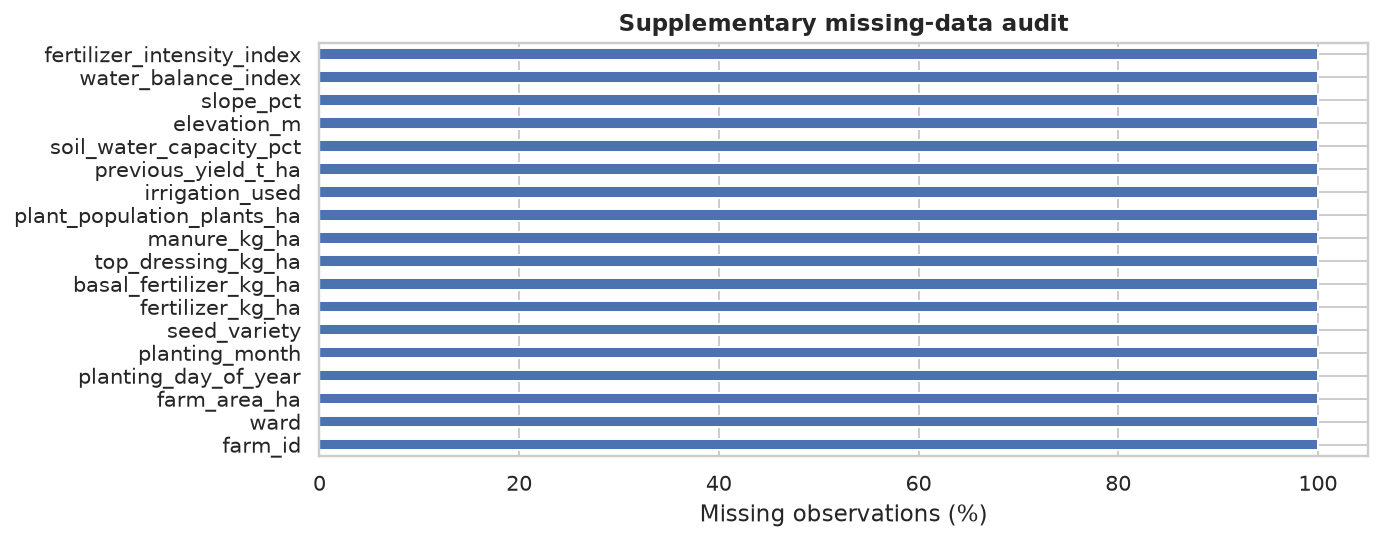

In [7]:
from integration.temporal_join import aggregate_nasa, aggregate_chirps
nasa_daily = pd.read_csv(DATA / "interim/nasa_power_daily.csv")
chirps_daily = pd.read_csv(DATA / "interim/chirps_daily.csv")
for label, daily, rebuilt, saved in [
    ("NASA POWER", nasa_daily, aggregate_nasa(nasa_daily, config), nasa),
    ("CHIRPS", chirps_daily, aggregate_chirps(chirps_daily, config), chirps),
]:
    pd.testing.assert_frame_equal(rebuilt.reset_index(drop=True), saved.reset_index(drop=True),
                                  check_dtype=False, rtol=1e-8, atol=1e-8)
    dates = pd.to_datetime(daily["date"])
    print(label, "seasonal reconstruction matches; daily range:", dates.min(), dates.max(),
          "duplicate dates:", int(dates.duplicated().sum()))
assert frame["year"].is_unique
joined_yield = frame[["year", "yield_t_ha"]].merge(
    faostat[["year", "yield_t_ha"]], on="year", suffixes=("_model", "_source"), validate="one_to_one")
np.testing.assert_allclose(joined_yield["yield_t_ha_model"], joined_yield["yield_t_ha_source"])
print("National yield join matches source exactly.")
missing_audit = pd.DataFrame({"missing": frame.isna().sum(), "missing_pct": frame.isna().mean()*100,
                              "distinct_values": frame.nunique()})
display(missing_audit)
fig, ax = plt.subplots(figsize=(10, 4))
missing_audit.query("missing > 0")["missing_pct"].sort_values().plot.barh(ax=ax)
ax.set(xlabel="Missing observations (%)", title="Supplementary missing-data audit")
plt.tight_layout(); plt.show()


## 4. Features, collinearity, and the year split

Soil properties do not change across the 24 seasons, so they are reported and then left out of the model matrix. Temperature range is the difference between the seasonal mean maximum and the seasonal mean minimum, so those three columns are linearly dependent. The tree models can still split on them. A linear model cannot separate them.

The most recent four harvest years are the test set. The four years before that are the validation set used to choose the algorithm. Earlier years are the training set. The test years are not used to choose the model or the tree settings.

In [4]:
features = usable_features(frame)
print("Model features:", features)
soil_cols = ["soil_ph", "soil_nitrogen_g_kg", "soil_organic_carbon_g_kg", "soil_clay_pct", "soil_sand_pct", "soil_silt_pct", "soil_cec_cmol_kg", "soil_bulk_density_g_cm3"]
print("Distinct soil values:")
print(frame[soil_cols].nunique().to_string())

vif_rows = []
x = frame[features].astype(float)
for column in features:
    others = [name for name in features if name != column]
    fitted = LinearRegression().fit(x[others], x[column])
    score = float(fitted.score(x[others], x[column]))
    vif = float("inf") if score > 0.999999 else 1.0 / (1.0 - score)
    vif_rows.append({"feature": column, "r2_on_others": round(score, 3), "vif": None if np.isinf(vif) else round(vif, 2)})
vif_table = pd.DataFrame(vif_rows)
print(vif_table.to_string(index=False))

masks = annual_masks(frame)
print("Train", masks["train_years"][0], "-", masks["train_years"][-1], "n =", len(masks["train_years"]))
print("Validation", masks["validation_years"])
print("Test", masks["test_years"])

dictionary = pd.DataFrame([
    ["year", "Harvest year used as the join key", "year", "Calendar rule on the November-March season"],
    ["season", "Season label, for example 2019/2020", "label", "Derived from the harvest year"],
    ["yield_t_ha", "Zimbabwe maize yield, the target", "t/ha", "FAOSTAT, kg/ha divided by 1000"],
    ["production_tonnes", "National maize production", "tonnes", "FAOSTAT"],
    ["season_rainfall_mm", "November-March rainfall total", "mm", "CHIRPS, NASA POWER only if CHIRPS is missing"],
    ["critical_period_rainfall_mm", "January-February rainfall", "mm", "CHIRPS"],
    ["rainfall_days", "Days with rainfall above 1 mm", "days", "CHIRPS"],
    ["rainfall_cv", "Coefficient of variation of daily rainfall", "ratio", "CHIRPS"],
    ["avg_temperature_c", "Mean of daily mean temperature", "°C", "NASA POWER T2M"],
    ["max_temperature_c", "Mean of daily maximum temperature", "°C", "NASA POWER T2M_MAX"],
    ["min_temperature_c", "Mean of daily minimum temperature", "°C", "NASA POWER T2M_MIN"],
    ["temperature_range_c", "max_temperature_c minus min_temperature_c", "°C", "Engineered from NASA POWER"],
    ["heat_stress_days", "Days with maximum temperature of at least 33 °C", "days", "NASA POWER"],
    ["soil_ph", "Topsoil pH, 0-5 cm, constant across years", "pH", "SoilGrids 2.0"],
    ["soil_nitrogen_g_kg", "Topsoil nitrogen, constant across years", "g/kg", "SoilGrids 2.0"],
    ["soil_organic_carbon_g_kg", "Topsoil organic carbon, constant across years", "g/kg", "SoilGrids 2.0"],
])
dictionary.columns = ["variable", "meaning", "unit", "source"]
dictionary.to_csv(ROOT / "reports" / "chapter3" / "data_dictionary.csv", index=False)
dictionary


Model features: ['season_rainfall_mm', 'critical_period_rainfall_mm', 'rainfall_cv', 'rainfall_days', 'avg_temperature_c', 'max_temperature_c', 'min_temperature_c', 'temperature_range_c', 'heat_stress_days']
Distinct soil values:
soil_ph                     1
soil_nitrogen_g_kg          1
soil_organic_carbon_g_kg    1
soil_clay_pct               1
soil_sand_pct               1
soil_silt_pct               1
soil_cec_cmol_kg            1
soil_bulk_density_g_cm3     1
                    feature  r2_on_others    vif
         season_rainfall_mm         0.891   9.18
critical_period_rainfall_mm         0.673   3.06
                rainfall_cv         0.923  12.95
              rainfall_days         0.970  32.81
          avg_temperature_c         0.995 220.05
          max_temperature_c         1.000    NaN
          min_temperature_c         1.000    NaN
        temperature_range_c         1.000    NaN
           heat_stress_days         0.629   2.70
Train 2000 - 2015 n = 16
Validation [201

,variable,meaning,unit,source
0,year,Harvest year used as the join key,year,Calendar rule on the November-March season
1,season,"Season label, for example 2019/2020",label,Derived from the harvest year
2,yield_t_ha,"Zimbabwe maize yield, the target",t/ha,"FAOSTAT, kg/ha divided by 1000"
3,production_tonnes,National maize production,tonnes,FAOSTAT
4,season_rainfall_mm,November-March rainfall total,mm,"CHIRPS, NASA POWER only if CHIRPS is missing"
5,critical_period_rainfall_mm,January-February rainfall,mm,CHIRPS
6,rainfall_days,Days with rainfall above 1 mm,days,CHIRPS
7,rainfall_cv,Coefficient of variation of daily rainfall,ratio,CHIRPS
8,avg_temperature_c,Mean of daily mean temperature,°C,NASA POWER T2M
9,max_temperature_c,Mean of daily maximum temperature,°C,NASA POWER T2M_MAX


### Supplementary model implementation and split checks

The following implementation fixes candidate settings, preprocessing and the annual split. Median imputation is fit inside each training pipeline and standardisation is used for linear regression. Constant soil and absent management predictors are excluded by the existing feature rule. Production totals and the target are not model inputs. All feature and split rules are preserved for comparability with the document.

In [9]:
import inspect
from models import real_training
for function in [real_training.usable_features, real_training.annual_masks, real_training._candidates]:
    display(Code(inspect.getsource(function), language="python"))
assert max(masks["train_years"]) < min(masks["validation_years"])
assert max(masks["validation_years"]) < min(masks["test_years"])
display(pd.DataFrame({"year": frame["year"], "split": np.select(
    [masks["train"], masks["validation"], masks["test"]],
    ["train", "validation", "test"], default="unused")}))


def usable_features(frame: pd.DataFrame) -> list[str]:
    chosen = []
    for column in MODEL_CANDIDATE_FEATURES:
        if column not in frame.columns:
            continue
        values = pd.to_numeric(frame[column], errors="coerce")
        if values.notna().sum() >= 4 and values.nunique(dropna=True) >= 2:
            chosen.append(column)
    return chosen

def annual_masks(frame: pd.DataFrame) -> dict:
    """Hold out later harvest years. One row per year cannot use a single-year validation score."""
    years = sorted(int(year) for year in frame["year"].dropna().unique())
    if len(years) < 8:
        raise ValueError("The real series needs at least eight harvest years before a temporal split.")
    test_n = max(3, len(years) // 5)
    valid_n = max(3, len(years) // 5)
    test_years = years[-test_n:]
    valid_years = years[-(test_n + valid_n):-test_n]
    train_years = years[: -(test_n + valid_n)]
    year = frame["year"].astype(int)
    return {
        "train": year.isin(train_years),
        "validation": year.isin(valid_years),
        "test": year.isin(test_years),
        "train_years": train_years,
        "validation_years": valid_years,
        "test_years": test_years,
    }

def _candidates(seed: int) -> dict:
    return {
        "Linear Regression": Pipeline(
            [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("model", LinearRegression())]
        ),
        "Decision Tree Regressor": Pipeline(
            [
                ("imputer", SimpleImputer(strategy="median")),
                ("model", DecisionTreeRegressor(max_depth=3, min_samples_leaf=3, random_state=seed)),
            ]
        ),
        "Random Forest Regressor": Pipeline(
            [
                ("imputer", SimpleImputer(strategy="median")),
                ("model", RandomForestRegressor(n_estimators=200, max_depth=4, min_samples_leaf=2, random_state=seed, n_jobs=1)),
            ]
        ),
        "Gradient Boosting Regressor": Pipeline(
            [
                ("imputer", SimpleImputer(strategy="median")),
                ("model", GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=2, random_state=seed)),
            ]
        ),
    }

,year,split
0,2000,train
1,2001,train
2,2002,train
3,2003,train
4,2004,train
5,2005,train
6,2006,train
7,2007,train
8,2008,train
9,2009,train


## 5. Descriptive analysis

Yield, rainfall, and temperature are summarised for the 24 modelling seasons. Pearson and Spearman correlations describe linear and rank association with national yield. A Shapiro–Wilk test checks the yield distribution. A Mann–Whitney test compares yield in the driest quarter of seasons with the other seasons. A Kendall test looks for a monotonic yield trend. These tests describe the table. They do not identify causes.

In [5]:
numeric = ["yield_t_ha", "season_rainfall_mm", "critical_period_rainfall_mm", "rainfall_days", "rainfall_cv", "avg_temperature_c", "max_temperature_c", "min_temperature_c", "temperature_range_c", "heat_stress_days"]
description = frame[numeric].agg(["count", "mean", "median", "std", "min", "max", "skew"]).T.round(3)
description.to_csv(ROOT / "reports" / "chapter3" / "descriptive_statistics.csv")
print(description.to_string())

associations = []
for column in features:
    pearson = float(frame[column].corr(frame["yield_t_ha"], method="pearson"))
    spearman = float(frame[column].corr(frame["yield_t_ha"], method="spearman"))
    associations.append({"feature": column, "pearson": round(pearson, 3), "spearman": round(spearman, 3)})
association_table = pd.DataFrame(associations).sort_values("pearson", key=lambda s: s.abs(), ascending=False)
print(association_table.to_string(index=False))

shapiro_w, shapiro_p = stats.shapiro(frame["yield_t_ha"])
quartile = float(frame["season_rainfall_mm"].quantile(0.25))
low_mask = frame["season_rainfall_mm"] <= quartile
mann_u, mann_p = stats.mannwhitneyu(frame.loc[low_mask, "yield_t_ha"], frame.loc[~low_mask, "yield_t_ha"], alternative="two-sided")
kendall_tau, kendall_p = stats.kendalltau(frame["year"], frame["yield_t_ha"])
print("Shapiro-Wilk yield W", round(float(shapiro_w), 4), "p", round(float(shapiro_p), 4))
print("Lowest rainfall quartile", round(quartile, 1), "mm; seasons", int(low_mask.sum()))
print("Mean yield in drier seasons", round(float(frame.loc[low_mask, "yield_t_ha"].mean()), 3))
print("Mean yield in other seasons", round(float(frame.loc[~low_mask, "yield_t_ha"].mean()), 3))
print("Mann-Whitney U", round(float(mann_u), 2), "p", round(float(mann_p), 4))
print("Kendall tau", round(float(kendall_tau), 3), "p", round(float(kendall_p), 4))

fig, axes = plt.subplots(2, 1, figsize=(9.2, 6.4), sharex=True)
axes[0].plot(frame["year"], frame["yield_t_ha"], color=GREEN, marker="o", linewidth=1.6)
axes[0].set_ylabel("National maize yield (t/ha)")
axes[0].set_title("FAOSTAT Zimbabwe maize yield by harvest year")
axes[1].bar(frame["year"], frame["season_rainfall_mm"], color=EARTH, width=0.7)
axes[1].set_ylabel("CHIRPS seasonal rainfall (mm)")
axes[1].set_xlabel("Harvest year")
axes[1].set_title("Macheke study-area rainfall, November to March")
fig.tight_layout()
fig.savefig(FIG / "fig_3_3_yield_and_rainfall.png", bbox_inches="tight", facecolor="white")
plt.close(fig)

corr = frame[features + ["yield_t_ha"]].corr()
fig, ax = plt.subplots(figsize=(8.6, 7.0))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, annot_kws={"size": 8})
ax.set_title("Pearson correlations among climate features and national yield")
fig.tight_layout()
fig.savefig(FIG / "fig_3_4_correlation_matrix.png", bbox_inches="tight", facecolor="white")
plt.close(fig)


                             count     mean   median      std      min       max   skew
yield_t_ha                    24.0    0.880    0.828    0.334    0.287     1.534  0.238
season_rainfall_mm            24.0  732.764  701.021  172.408  458.846  1062.390  0.516
critical_period_rainfall_mm   24.0  356.772  363.077  119.196  134.948   538.057 -0.194
rainfall_days                 24.0   60.958   58.500   12.390   42.000    83.000  0.127
rainfall_cv                   24.0    1.767    1.757    0.303    1.341     2.460  0.419
avg_temperature_c             24.0   21.022   20.912    0.619   20.151    22.491  0.879
max_temperature_c             24.0   27.293   27.018    1.063   25.999    29.381  0.529
min_temperature_c             24.0   15.754   15.785    0.395   15.242    16.589  0.430
temperature_range_c           24.0   11.539   11.477    0.987    9.845    13.268  0.020
heat_stress_days              24.0    5.292    4.500    5.982    0.000    27.000  2.256
                    feature  pea

### Supplementary exploratory visualisations

Distributions, boxplots and pairwise plots describe the real observations. Scatter plots include all seasons and do not imply causation. The source data have no changing farm-management or soil observations, so those effects cannot be estimated here. EDA uses the complete historical series descriptively; model fitting and selection retain the original chronological split.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


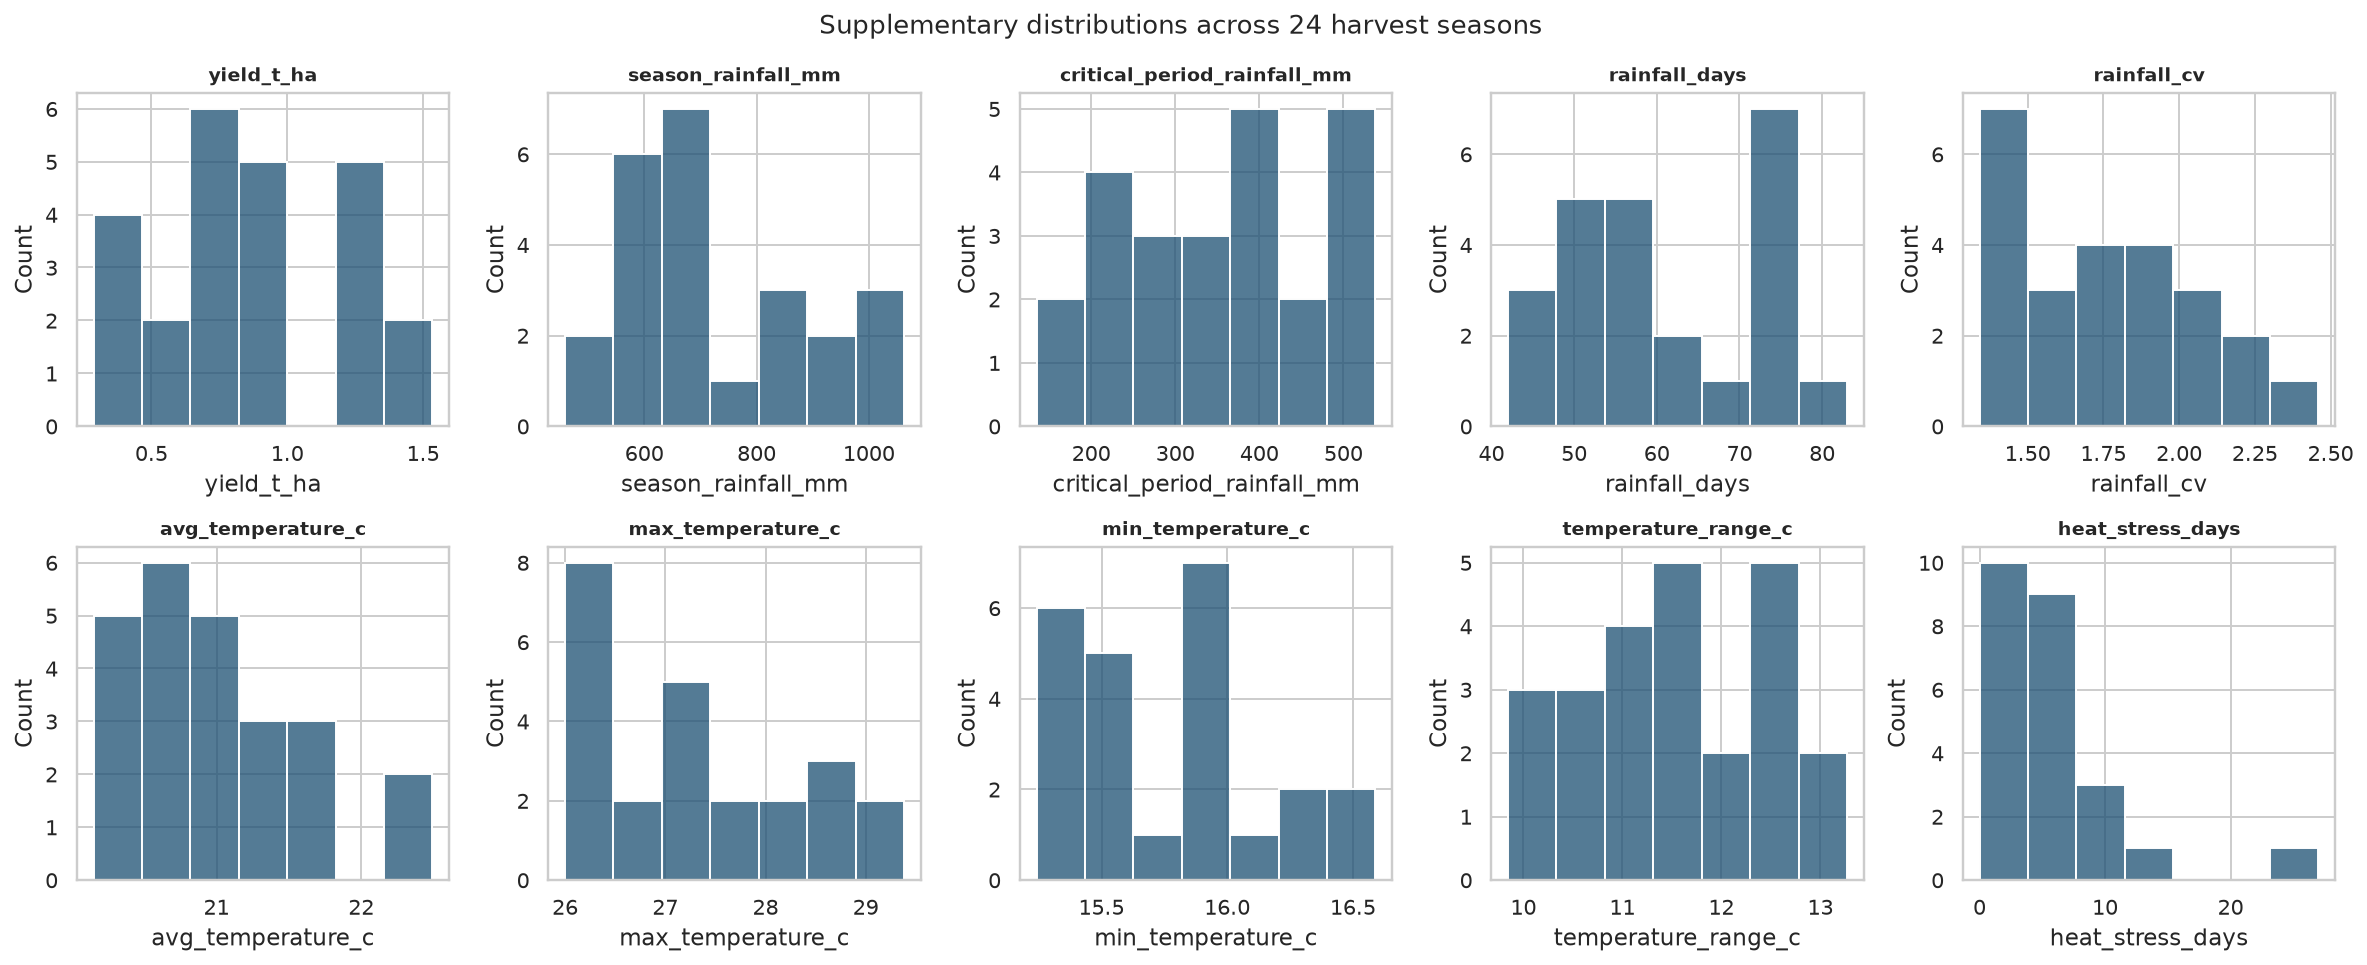

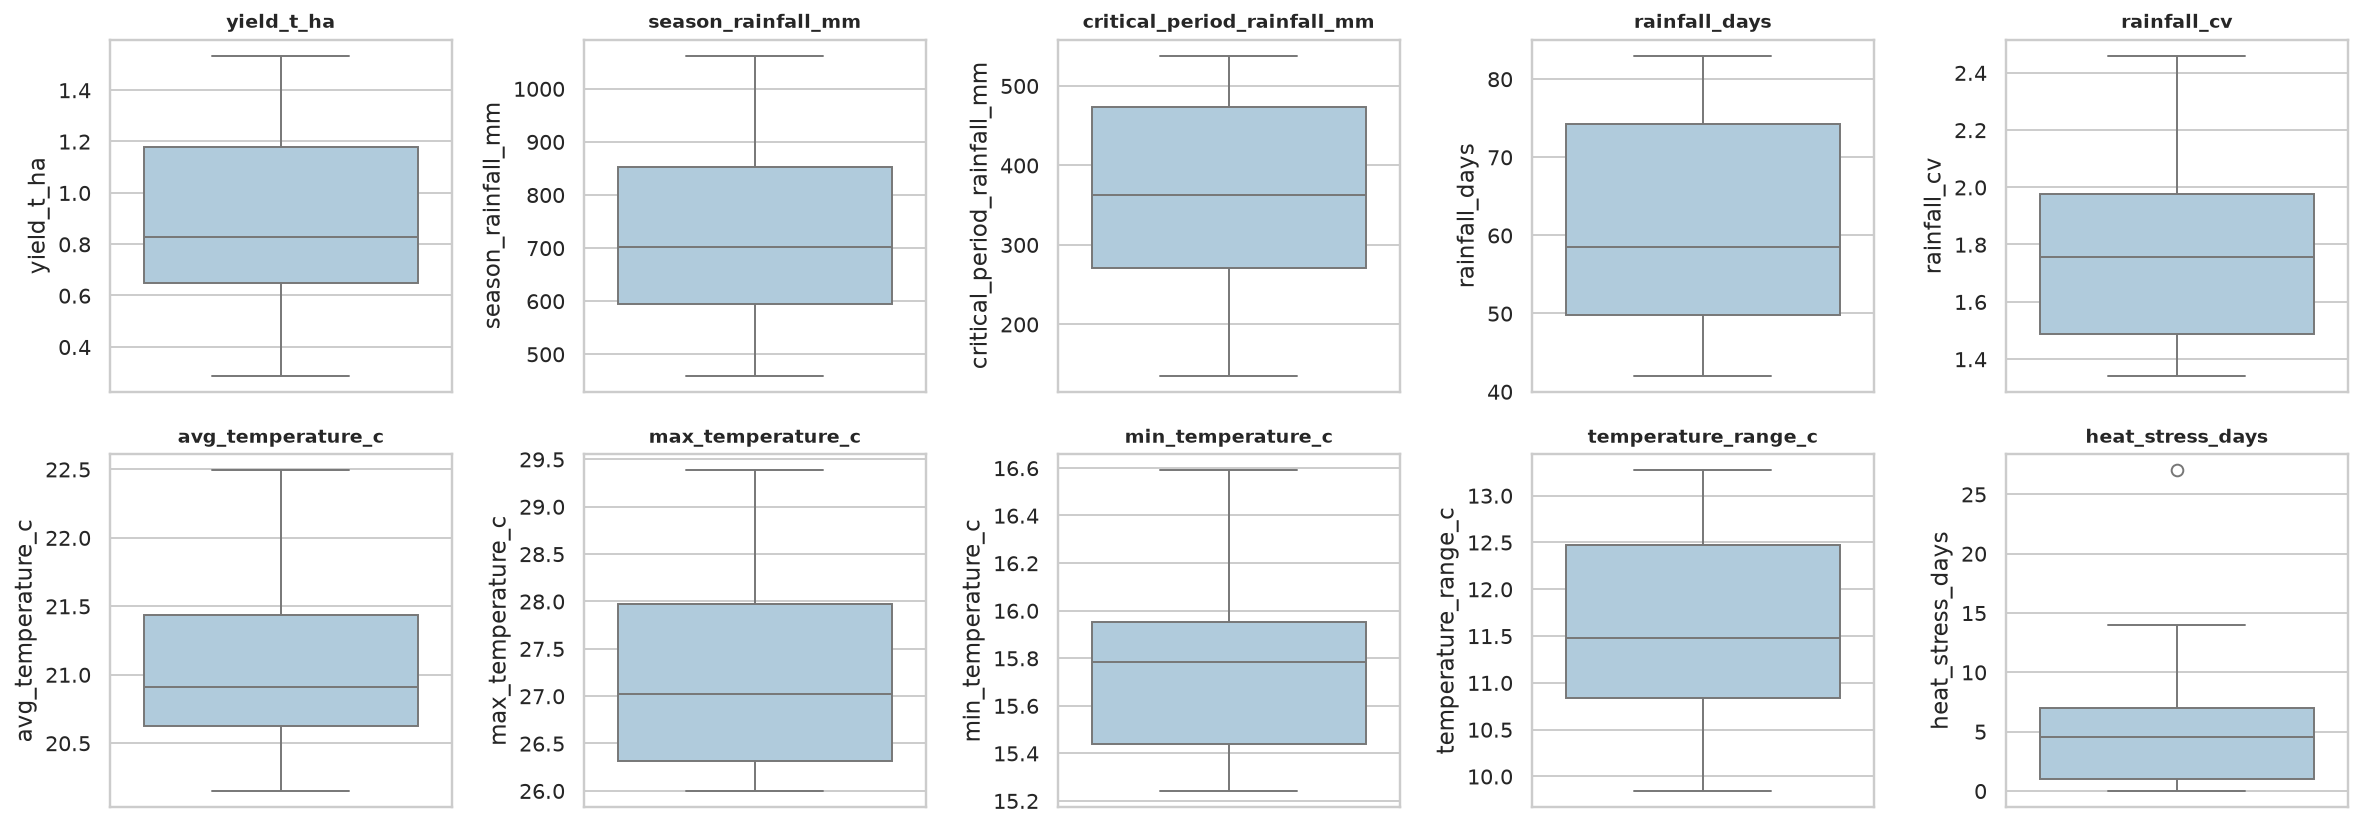

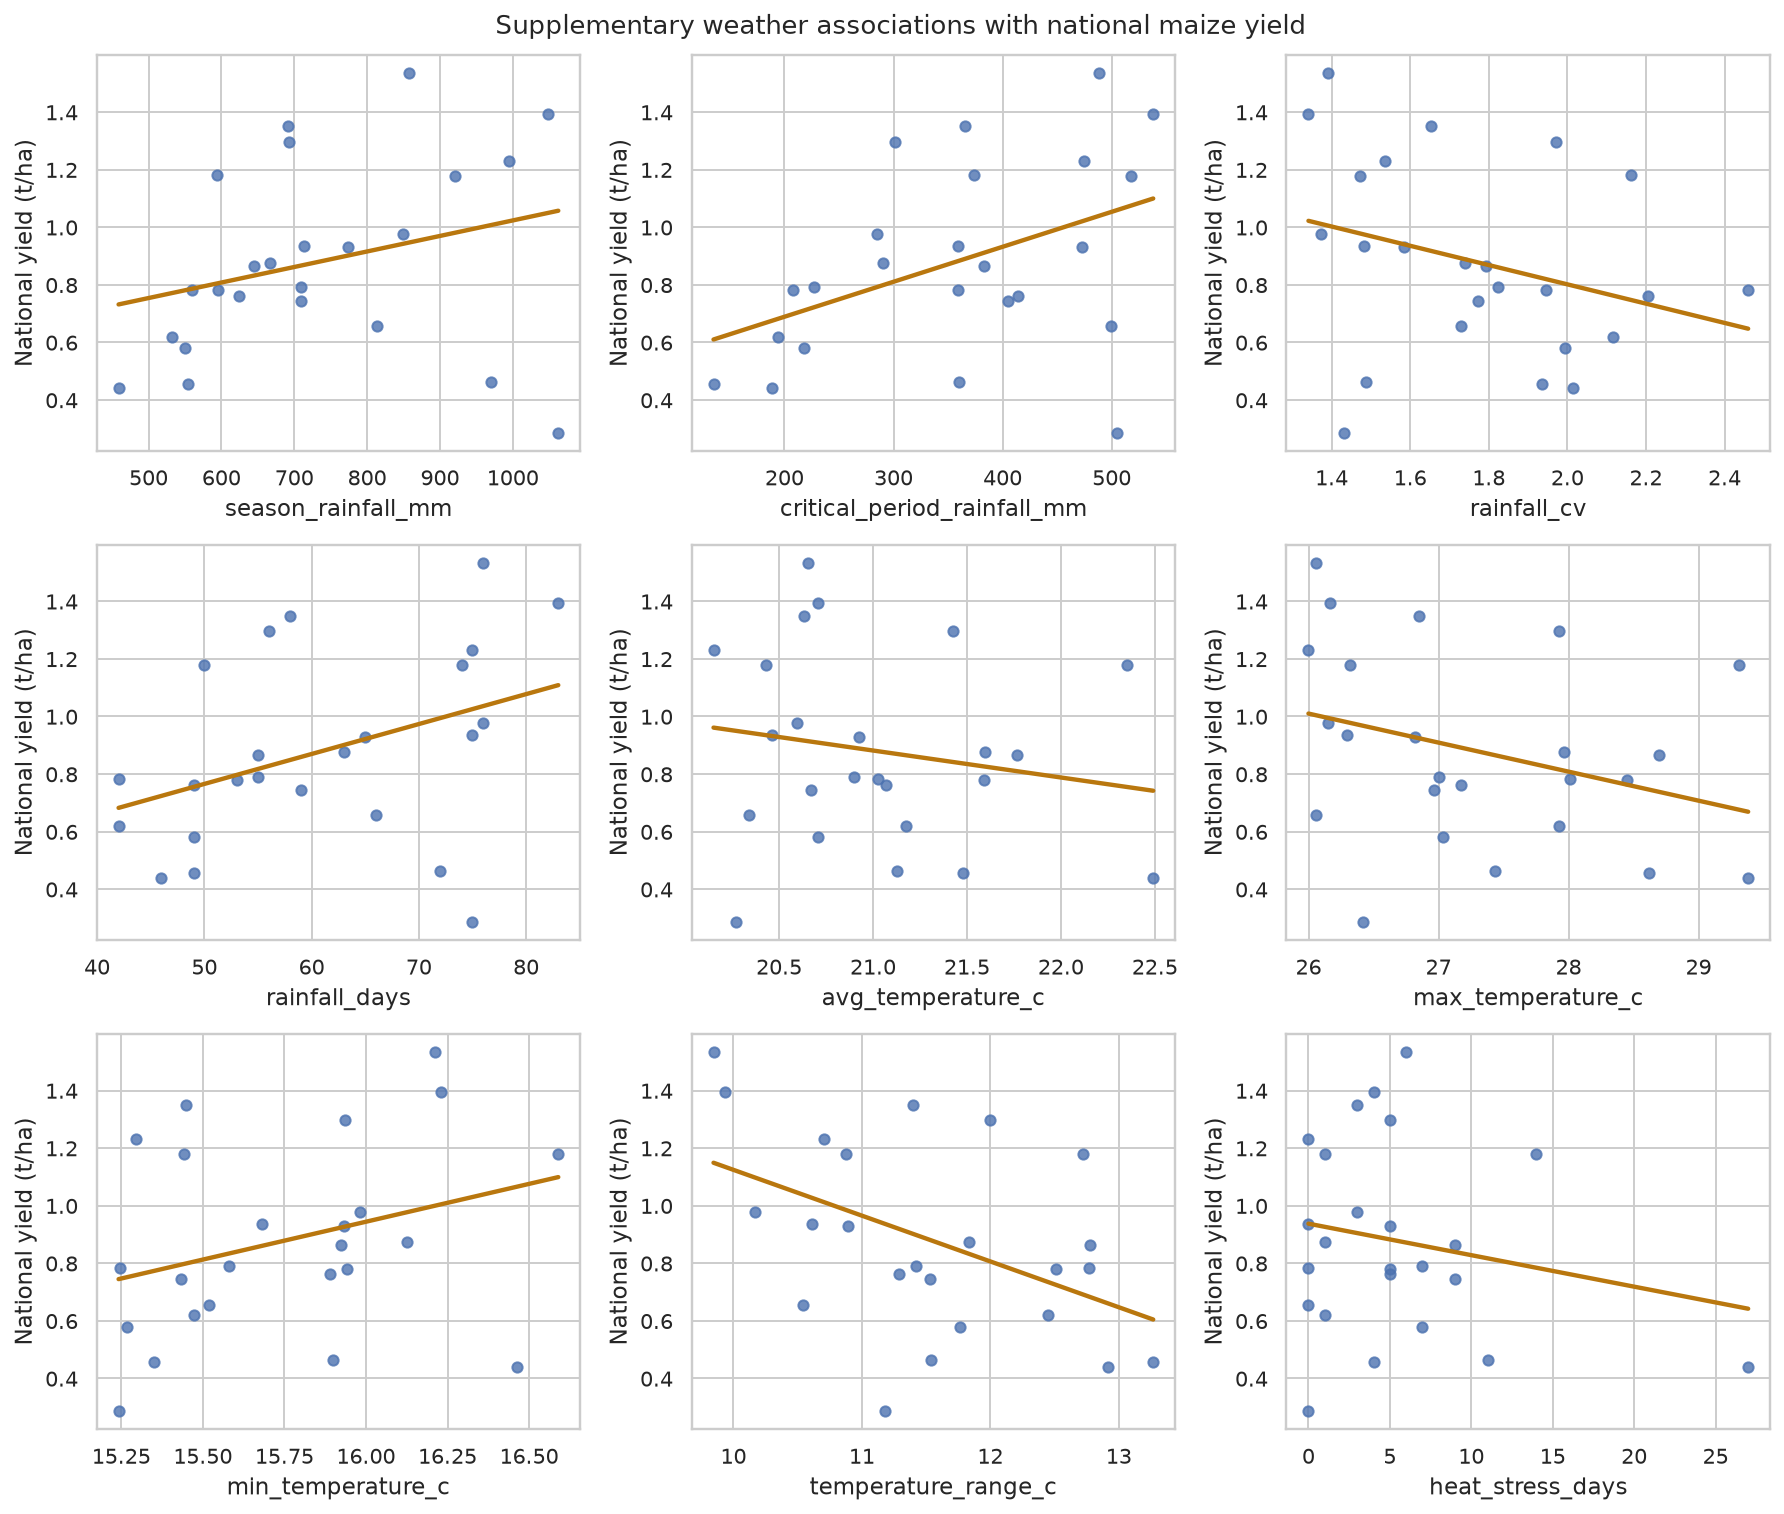

,feature,pearson,spearman
7,temperature_range_c,-0.470,-0.470
1,critical_period_rainfall_mm,0.433,0.389
3,rainfall_days,0.385,0.484
5,max_temperature_c,-0.321,-0.402
6,min_temperature_c,0.311,0.383
2,rainfall_cv,-0.303,-0.375
0,season_rainfall_mm,0.278,0.368
8,heat_stress_days,-0.196,-0.110
4,avg_temperature_c,-0.173,-0.207


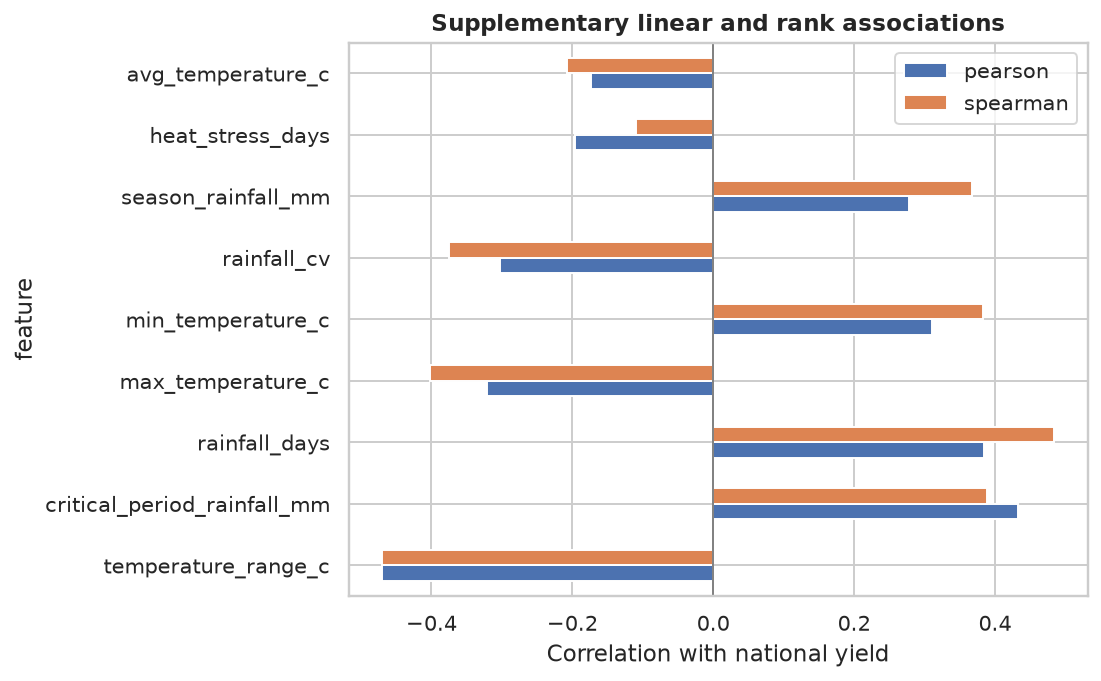

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for ax, column in zip(axes.flat, numeric):
    sns.histplot(frame[column].dropna(), bins=7, ax=ax, color=NAVY)
    ax.set_title(column, fontsize=10)
fig.suptitle("Supplementary distributions across 24 harvest seasons")
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(2, 5, figsize=(17, 6))
for ax, column in zip(axes.flat, numeric):
    sns.boxplot(y=frame[column], ax=ax, color="#A9CCE3")
    ax.set_title(column, fontsize=10)
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(3, 3, figsize=(13, 11))
for ax, column in zip(axes.flat, features):
    sns.regplot(data=frame, x=column, y="yield_t_ha", ci=None, ax=ax,
                scatter_kws={"s": 28}, line_kws={"color": EARTH})
    ax.set_ylabel("National yield (t/ha)")
for ax in list(axes.flat)[len(features):]: ax.set_visible(False)
fig.suptitle("Supplementary weather associations with national maize yield")
plt.tight_layout(); plt.show()
display(association_table)
fig, ax = plt.subplots(figsize=(8, 5))
association_table.set_index("feature")[["pearson", "spearman"]].plot.barh(ax=ax)
ax.axvline(0, color="grey", linewidth=1)
ax.set(xlabel="Correlation with national yield", title="Supplementary linear and rank associations")
plt.tight_layout(); plt.show()


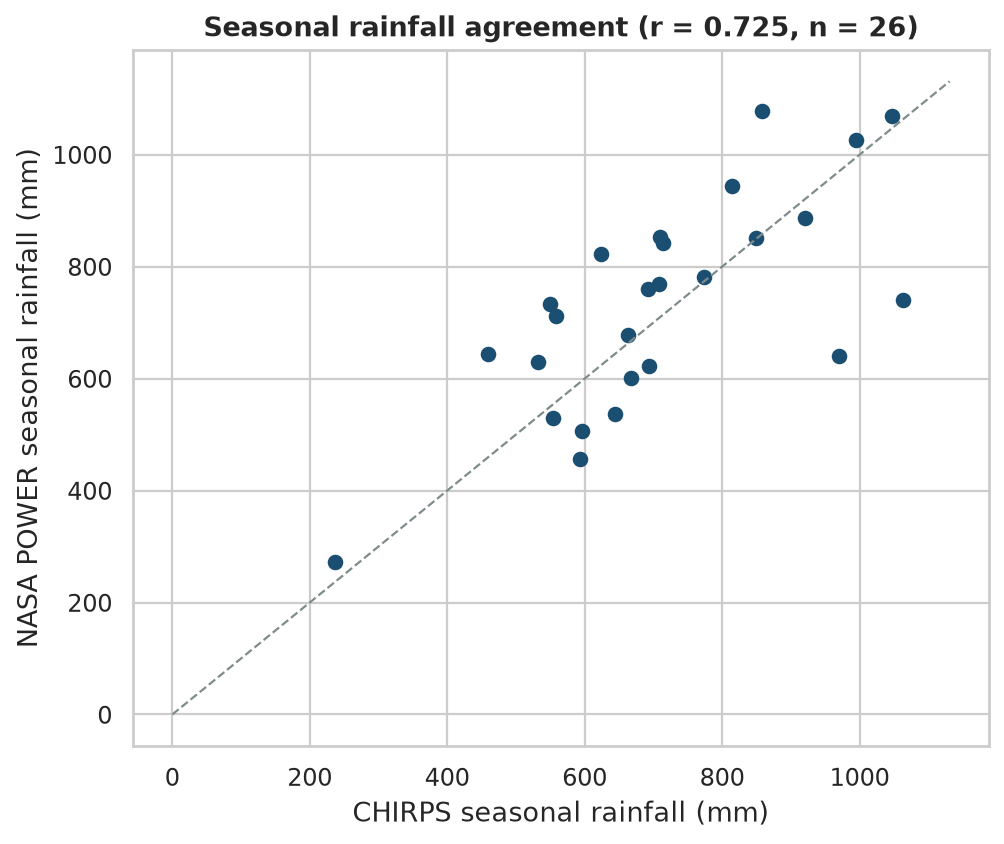

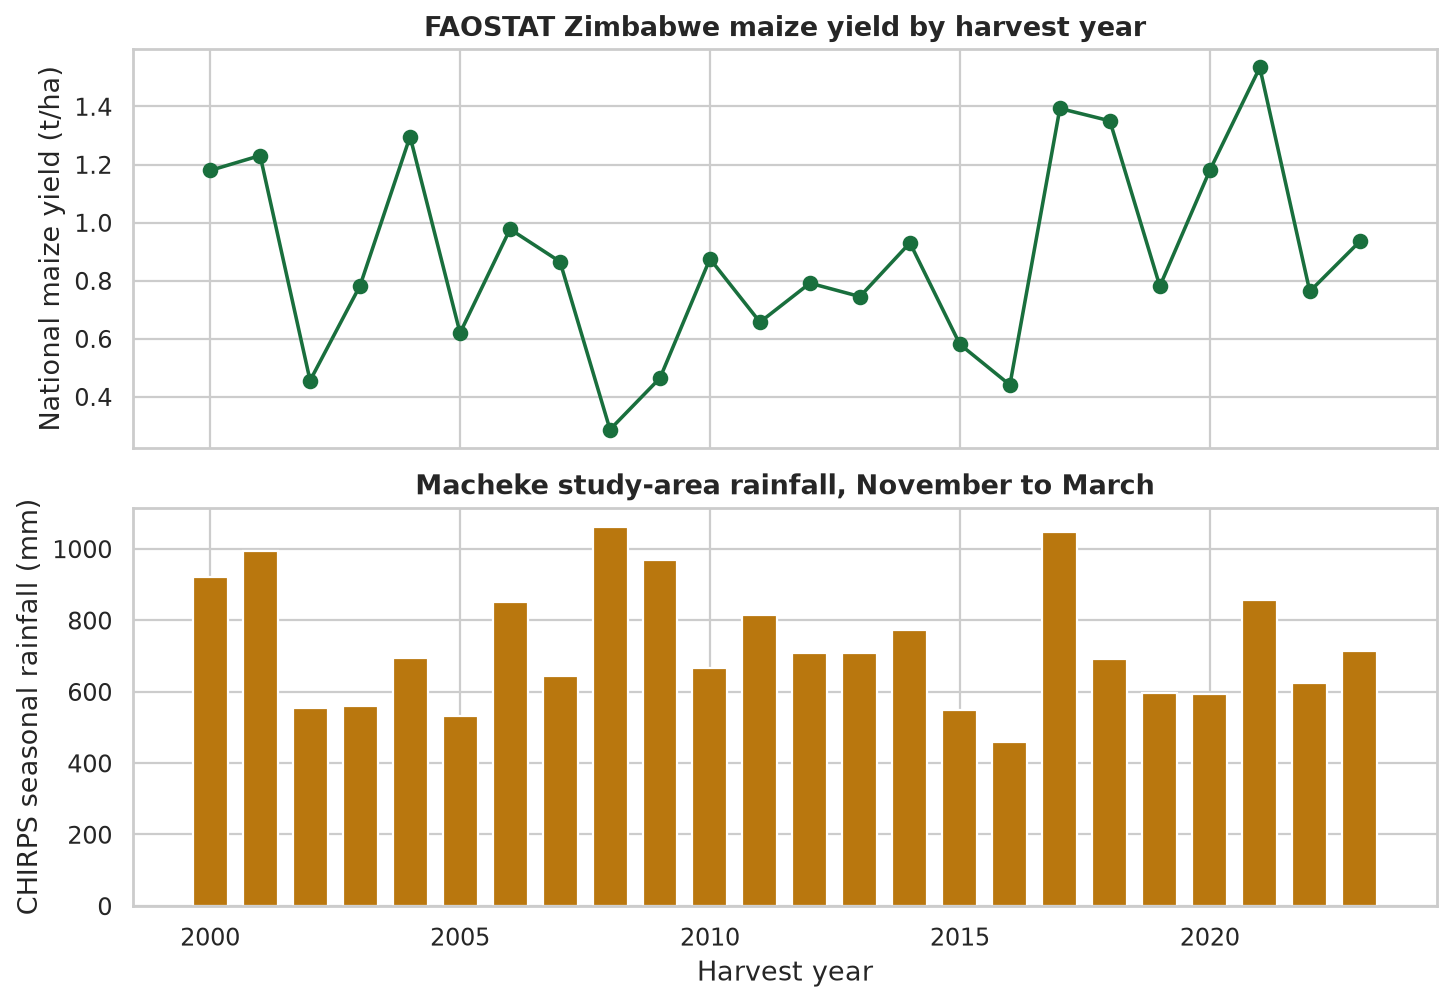

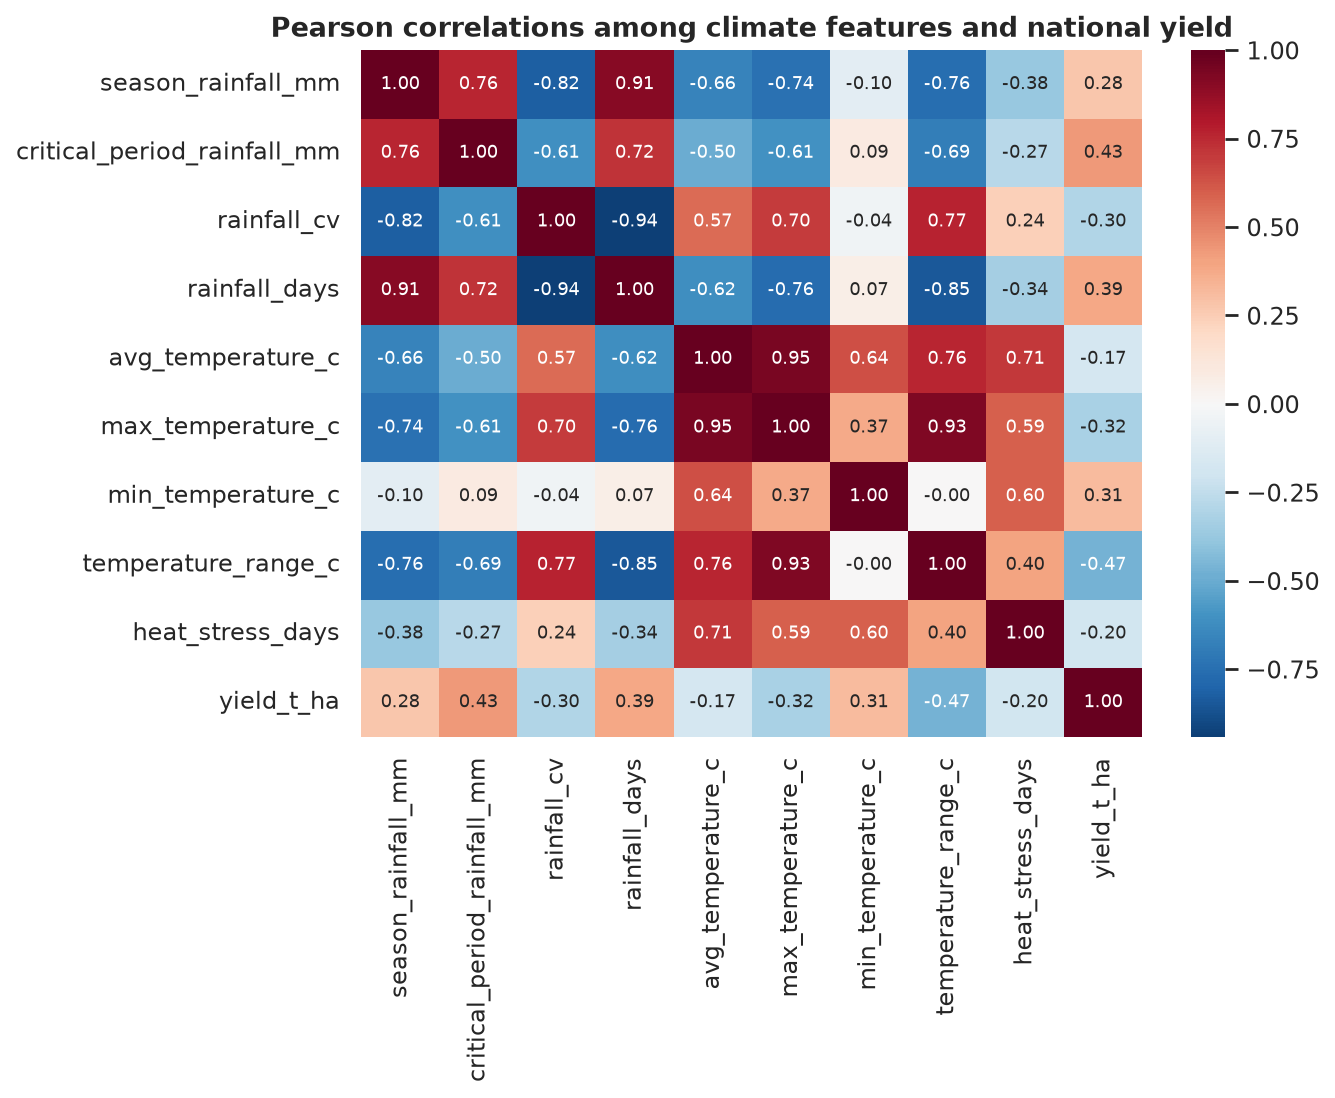

In [12]:
from IPython.display import Image as NotebookImage
for filename in ["fig_3_2_rainfall_agreement.png", "fig_3_3_yield_and_rainfall.png", "fig_3_4_correlation_matrix.png"]:
    display(NotebookImage(filename=str(FIG / filename)))


## 6. Models, tuning, and the held-out seasons

Four regressors are compared: ordinary least squares, a depth-limited decision tree, a random forest, and gradient boosting. Each pipeline median-imputes inside the training fold. The linear model is also standardised. A training-mean baseline and a linear time trend are scored on the same years.

Algorithm choice uses validation years 2016–2019 only. An expanding window then scores one-year-ahead predictions for 2008–2019, pooled into one MAE, RMSE, and R². Those folds stop before 2020. A small random-forest grid (200 or 100 trees, depth 2–4, minimum leaf 2 or 3) is scored on the validation years. The saved settings stay in place when the grid does not improve validation RMSE by a meaningful amount. The test years 2020–2023 are scored once.

In [6]:
def regression_scores(y_true, y_pred):
    return {
        "mae": round(float(mean_absolute_error(y_true, y_pred)), 4),
        "rmse": round(float(mean_squared_error(y_true, y_pred) ** 0.5), 4),
        "r2": round(float(r2_score(y_true, y_pred)), 4),
    }


y = frame["yield_t_ha"]
x = frame[features]
train, valid, test = masks["train"], masks["validation"], masks["test"]
candidates = _candidates(RANDOM_SEED)
rows = []
fitted = {}
for name, model in candidates.items():
    model.fit(x.loc[train], y.loc[train])
    scores = regression_scores(y.loc[valid], model.predict(x.loc[valid]))
    rows.append({"model_name": name, **{f"validation_{key}": value for key, value in scores.items()}})
    fitted[name] = model
comparison = pd.DataFrame(rows).sort_values(["validation_r2", "validation_rmse"], ascending=[False, True]).reset_index(drop=True)
chosen_name = str(comparison.loc[0, "model_name"])
chosen = fitted[chosen_name]

mean_baseline = {
    "validation": regression_scores(y.loc[valid], np.full(int(valid.sum()), float(y.loc[train].mean()))),
    "test": regression_scores(y.loc[test], np.full(int(test.sum()), float(y.loc[train].mean()))),
}
trend = LinearRegression().fit(frame.loc[train, ["year"]], y.loc[train])
trend_baseline = {
    "validation": regression_scores(y.loc[valid], trend.predict(frame.loc[valid, ["year"]])),
    "test": regression_scores(y.loc[test], trend.predict(frame.loc[test, ["year"]])),
}

development = frame.loc[frame["year"] <= 2019].sort_values("year").reset_index(drop=True)
pooled = []
for name, model in _candidates(RANDOM_SEED).items():
    predictions = []
    actual = []
    for end in range(8, len(development)):
        fold = clone(model)
        past = development.iloc[:end]
        future = development.iloc[end:end + 1]
        fold.fit(past[features], past["yield_t_ha"])
        predictions.append(float(fold.predict(future[features])[0]))
        actual.append(float(future["yield_t_ha"].iloc[0]))
    pooled.append({"model_name": name, "one_step_years": "2008-2019", "n_forecasts": len(actual), **regression_scores(actual, predictions)})
expanding = pd.DataFrame(pooled).sort_values("rmse").reset_index(drop=True)

grid_rows = []
for trees, depth, leaf in [(100, 2, 2), (100, 3, 2), (100, 4, 2), (100, 2, 3), (100, 3, 3), (100, 4, 3), (200, 2, 2), (200, 3, 2), (200, 4, 2), (200, 2, 3), (200, 3, 3), (200, 4, 3)]:
    forest = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(n_estimators=trees, max_depth=depth, min_samples_leaf=leaf, random_state=RANDOM_SEED, n_jobs=1)),
    ])
    forest.fit(x.loc[train], y.loc[train])
    scores = regression_scores(y.loc[valid], forest.predict(x.loc[valid]))
    grid_rows.append({"n_estimators": trees, "max_depth": depth, "min_samples_leaf": leaf, **{f"validation_{key}": value for key, value in scores.items()}})
grid = pd.DataFrame(grid_rows).sort_values("validation_rmse").reset_index(drop=True)
preset = grid.loc[(grid["n_estimators"] == 200) & (grid["max_depth"] == 4) & (grid["min_samples_leaf"] == 2)].iloc[0]

test_pred = chosen.predict(x.loc[test])
test_scores = regression_scores(y.loc[test], test_pred)
importance = permutation_importance(chosen, x.loc[valid], y.loc[valid], n_repeats=10, random_state=RANDOM_SEED, scoring="r2")
importance_table = pd.DataFrame({"feature": features, "importance_mean": importance.importances_mean}).sort_values("importance_mean", ascending=False)
importance_table.insert(0, "rank", range(1, len(importance_table) + 1))

print("Validation comparison")
print(comparison.to_string(index=False))
print("Expanding-window pooled scores")
print(expanding.to_string(index=False))
print("Random forest grid, best five by validation RMSE")
print(grid.head(5).to_string(index=False))
print("Saved settings validation RMSE", float(preset["validation_rmse"]))
print("Chosen", chosen_name, "test", test_scores)
print("Training-mean baseline", mean_baseline)
print("Trend baseline", trend_baseline)
print(importance_table.round(4).to_string(index=False))

comparison.to_csv(ROOT / "reports" / "chapter3" / "model_comparison.csv", index=False)
grid.to_csv(ROOT / "reports" / "chapter3" / "random_forest_grid.csv", index=False)
save_table(comparison.round(4), FIG / "fig_3_5_model_comparison.png", "Notebook output: validation scores used to choose the algorithm")

fig, ax = plt.subplots(figsize=(8.0, 4.4))
order = comparison.sort_values("validation_rmse")
ax.barh(order["model_name"], order["validation_rmse"], color=NAVY)
ax.set_xlabel("Validation RMSE (t/ha), harvest years 2016-2019")
ax.set_title("Algorithm comparison on the validation seasons")
fig.tight_layout()
fig.savefig(FIG / "fig_3_5_validation_rmse.png", bbox_inches="tight", facecolor="white")
plt.close(fig)

test_frame = frame.loc[test, ["year", "yield_t_ha"]].copy()
test_frame["predicted_t_ha"] = test_pred
fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.4))
axes[0].scatter(test_frame["yield_t_ha"], test_frame["predicted_t_ha"], color=NAVY, s=50, zorder=3)
for row in test_frame.itertuples(index=False):
    axes[0].annotate(str(int(row.year)), (row.yield_t_ha, row.predicted_t_ha), textcoords="offset points", xytext=(5, 4), fontsize=8)
low = min(test_frame["yield_t_ha"].min(), test_frame["predicted_t_ha"].min()) - 0.1
high = max(test_frame["yield_t_ha"].max(), test_frame["predicted_t_ha"].max()) + 0.1
axes[0].plot([low, high], [low, high], color="#7F8C8D", linestyle="--")
axes[0].set_xlabel("FAOSTAT yield (t/ha)")
axes[0].set_ylabel("Predicted yield (t/ha)")
axes[0].set_title("Test seasons")
axes[1].plot(frame["year"], frame["yield_t_ha"], color=GREEN, marker="o", label="FAOSTAT")
axes[1].scatter(test_frame["year"], test_frame["predicted_t_ha"], color=NAVY, s=40, label="Test prediction", zorder=3)
axes[1].set_ylabel("Yield (t/ha)")
axes[1].set_xlabel("Harvest year")
axes[1].set_title("Held-out predictions")
axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "fig_3_6_test_predictions.png", bbox_inches="tight", facecolor="white")
plt.close(fig)

summary = {
    "n_seasons": int(len(frame)),
    "year_start": int(frame.year.min()),
    "year_end": int(frame.year.max()),
    "retrieval_date": "5 October 2026",
    "rain_corr": round(rain_corr, 3),
    "rain_corr_n": int(len(agreed)),
    "nasa_daily": int(len(pd.read_csv(DATA / "interim" / "nasa_power_daily.csv"))),
    "chirps_daily": int(len(pd.read_csv(DATA / "interim" / "chirps_daily.csv"))),
    "soil_rows": int(len(soil)),
    "faostat_years": int(len(faostat)),
    "faostat_year_min": int(faostat.year.min()),
    "faostat_year_max": int(faostat.year.max()),
    "faostat_flags": {str(k): int(v) for k, v in window["faostat_flag"].value_counts().items()},
    "faostat_x_years": [int(year) for year in window.loc[window["faostat_flag"] != "A", "year"]],
    "yield_mean": round(float(y.mean()), 3),
    "yield_median": round(float(y.median()), 3),
    "yield_std": round(float(y.std()), 3),
    "yield_min": round(float(y.min()), 3),
    "yield_max": round(float(y.max()), 3),
    "yield_min_year": int(frame.loc[y.idxmin(), "year"]),
    "yield_max_year": int(frame.loc[y.idxmax(), "year"]),
    "rain_mean": round(float(frame.season_rainfall_mm.mean()), 1),
    "rain_median": round(float(frame.season_rainfall_mm.median()), 1),
    "rain_std": round(float(frame.season_rainfall_mm.std()), 1),
    "rain_min": round(float(frame.season_rainfall_mm.min()), 1),
    "rain_max": round(float(frame.season_rainfall_mm.max()), 1),
    "rain_min_year": int(frame.loc[frame.season_rainfall_mm.idxmin(), "year"]),
    "rain_max_year": int(frame.loc[frame.season_rainfall_mm.idxmax(), "year"]),
    "temp_mean": round(float(frame.avg_temperature_c.mean()), 2),
    "temp_min": round(float(frame.avg_temperature_c.min()), 2),
    "temp_max": round(float(frame.avg_temperature_c.max()), 2),
    "heat_mean": round(float(frame.heat_stress_days.mean()), 1),
    "heat_max": int(frame.heat_stress_days.max()),
    "heat_max_year": int(frame.loc[frame.heat_stress_days.idxmax(), "year"]),
    "soil": {column: float(frame[column].iloc[0]) for column in soil_cols},
    "shapiro_w": round(float(shapiro_w), 3),
    "shapiro_p": round(float(shapiro_p), 3),
    "rain_q25": round(quartile, 1),
    "n_dry": int(low_mask.sum()),
    "yield_dry": round(float(frame.loc[low_mask, "yield_t_ha"].mean()), 3),
    "yield_other": round(float(frame.loc[~low_mask, "yield_t_ha"].mean()), 3),
    "mann_u": round(float(mann_u), 1),
    "mann_p": round(float(mann_p), 3),
    "kendall_tau": round(float(kendall_tau), 3),
    "kendall_p": round(float(kendall_p), 3),
    "train_years": [int(year) for year in masks["train_years"]],
    "validation_years": [int(year) for year in masks["validation_years"]],
    "test_years": [int(year) for year in masks["test_years"]],
    "chosen_model": chosen_name,
    "comparison": comparison.to_dict(orient="records"),
    "expanding": expanding.to_dict(orient="records"),
    "grid_best": grid.iloc[0].to_dict(),
    "grid_preset_rmse": float(preset["validation_rmse"]),
    "test_scores": test_scores,
    "mean_baseline": mean_baseline,
    "trend_baseline": trend_baseline,
    "test_predictions": test_frame.round(4).to_dict(orient="records"),
    "importance": importance_table.round(4).to_dict(orient="records"),
    "vif": vif_table.to_dict(orient="records"),
    "associations": association_table.to_dict(orient="records"),
    "description": description.reset_index().rename(columns={"index": "variable"}).to_dict(orient="records"),
    "management_missing": {column: float(frame[column].isna().mean()) for column in management},
    "versions": {
        "python": sys.version.split()[0],
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "scikit-learn": __import__("sklearn").__version__,
        "matplotlib": __import__("matplotlib").__version__,
        "scipy": __import__("scipy").__version__,
    },
    "random_seed": int(RANDOM_SEED),
    "r2_target": 0.8,
    "r2_target_met": bool(test_scores["r2"] >= 0.8),
}
(ROOT / "reports" / "chapter3" / "chapter3_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Summary written")


Validation comparison
                 model_name  validation_mae  validation_rmse  validation_r2
    Random Forest Regressor          0.3922           0.4181        -0.0950
Gradient Boosting Regressor          0.4981           0.5052        -0.5992
          Linear Regression          0.4351           0.5455        -0.8643
    Decision Tree Regressor          0.5134           0.5624        -0.9816
Expanding-window pooled scores
                 model_name one_step_years  n_forecasts    mae   rmse      r2
    Random Forest Regressor      2008-2019           12 0.2981 0.3931 -0.4859
Gradient Boosting Regressor      2008-2019           12 0.3627 0.4457 -0.9109
    Decision Tree Regressor      2008-2019           12 0.3812 0.4706 -1.1301
          Linear Regression      2008-2019           12 0.6059 0.8077 -5.2744
Random forest grid, best five by validation RMSE
 n_estimators  max_depth  min_samples_leaf  validation_mae  validation_rmse  validation_r2
          200          3             

### Recorded results and rerun provenance

The saved source notebook reports test MAE **0.2239**, RMSE **0.3030** and R² **−0.0931**. The attached document uses different rounding or an earlier run. Its images and the source notebook outputs are retained exactly. Re-execution under a different library environment may vary slightly. Supplementary diagnostics use the recorded predictions and metrics from `reports/chapter3/chapter3_summary.json`, embedded here as a fixed snapshot; they are not fresh fitted results.

In [14]:
recorded_results = {'test_scores': {'mae': 0.2239, 'rmse': 0.303, 'r2': -0.0931}, 'comparison': [{'model_name': 'Random Forest Regressor', 'validation_mae': 0.3922, 'validation_rmse': 0.4181, 'validation_r2': -0.095}, {'model_name': 'Gradient Boosting Regressor', 'validation_mae': 0.4981, 'validation_rmse': 0.5052, 'validation_r2': -0.5992}, {'model_name': 'Linear Regression', 'validation_mae': 0.4351, 'validation_rmse': 0.5455, 'validation_r2': -0.8643}, {'model_name': 'Decision Tree Regressor', 'validation_mae': 0.5134, 'validation_rmse': 0.5624, 'validation_r2': -0.9816}], 'expanding': [{'model_name': 'Random Forest Regressor', 'one_step_years': '2008-2019', 'n_forecasts': 12, 'mae': 0.2981, 'rmse': 0.3931, 'r2': -0.4859}, {'model_name': 'Gradient Boosting Regressor', 'one_step_years': '2008-2019', 'n_forecasts': 12, 'mae': 0.3627, 'rmse': 0.4457, 'r2': -0.9109}, {'model_name': 'Decision Tree Regressor', 'one_step_years': '2008-2019', 'n_forecasts': 12, 'mae': 0.3812, 'rmse': 0.4706, 'r2': -1.1301}, {'model_name': 'Linear Regression', 'one_step_years': '2008-2019', 'n_forecasts': 12, 'mae': 0.6059, 'rmse': 0.8077, 'r2': -5.2744}], 'test_predictions': [{'year': 2020, 'yield_t_ha': 1.1801, 'predicted_t_ha': 0.9121}, {'year': 2021, 'yield_t_ha': 1.5344, 'predicted_t_ha': 0.9945}, {'year': 2022, 'yield_t_ha': 0.7628, 'predicted_t_ha': 0.8129}, {'year': 2023, 'yield_t_ha': 0.935, 'predicted_t_ha': 0.8974}], 'importance': [{'rank': 1, 'feature': 'season_rainfall_mm', 'importance_mean': 0.0696}, {'rank': 2, 'feature': 'rainfall_days', 'importance_mean': 0.0387}, {'rank': 3, 'feature': 'critical_period_rainfall_mm', 'importance_mean': 0.0286}, {'rank': 4, 'feature': 'rainfall_cv', 'importance_mean': 0.0214}, {'rank': 5, 'feature': 'temperature_range_c', 'importance_mean': 0.0204}, {'rank': 6, 'feature': 'heat_stress_days', 'importance_mean': 0.0165}, {'rank': 7, 'feature': 'avg_temperature_c', 'importance_mean': 0.0019}, {'rank': 8, 'feature': 'max_temperature_c', 'importance_mean': -0.0042}, {'rank': 9, 'feature': 'min_temperature_c', 'importance_mean': -0.2147}]}
test_scores = recorded_results["test_scores"]
comparison = pd.DataFrame(recorded_results["comparison"])
expanding = pd.DataFrame(recorded_results["expanding"])
test_frame = pd.DataFrame(recorded_results["test_predictions"])
test_pred = test_frame["predicted_t_ha"].to_numpy()
importance_table = pd.DataFrame(recorded_results["importance"])


## 7. Supplementary evaluation and model interpretation

The fitted model and its held-out predictions are reused without retraining or changing any metric. The grid is reported as a sensitivity analysis; it does not replace the preserved candidate settings. Residuals are actual minus predicted yield, so positive residuals indicate underprediction. Four test seasons provide limited diagnostic evidence.

The yield-band confusion matrix below is an additional description of regression predictions. Its low, middle and high boundaries are the training yield tertiles, fixed before looking at test yields. It is not a classifier, adds no accuracy target, and does not replace MAE, RMSE or R².

,model_name,validation_mae,validation_rmse,validation_r2
0,Random Forest Regressor,0.3922,0.4181,-0.0950
1,Gradient Boosting Regressor,0.4981,0.5052,-0.5992
2,Linear Regression,0.4351,0.5455,-0.8643
3,Decision Tree Regressor,0.5134,0.5624,-0.9816


,model_name,one_step_years,n_forecasts,mae,rmse,r2
0,Random Forest Regressor,2008-2019,12,0.2981,0.3931,-0.4859
1,Gradient Boosting Regressor,2008-2019,12,0.3627,0.4457,-0.9109
2,Decision Tree Regressor,2008-2019,12,0.3812,0.4706,-1.1301
3,Linear Regression,2008-2019,12,0.6059,0.8077,-5.2744


The grid is reported in the original tuning section above.
Preserved held-out metrics: {'mae': 0.2239, 'rmse': 0.303, 'r2': -0.0931}


,year,yield_t_ha,predicted_t_ha
0,2020,1.1801,0.9121
1,2021,1.5344,0.9945
2,2022,0.7628,0.8129
3,2023,0.9350,0.8974


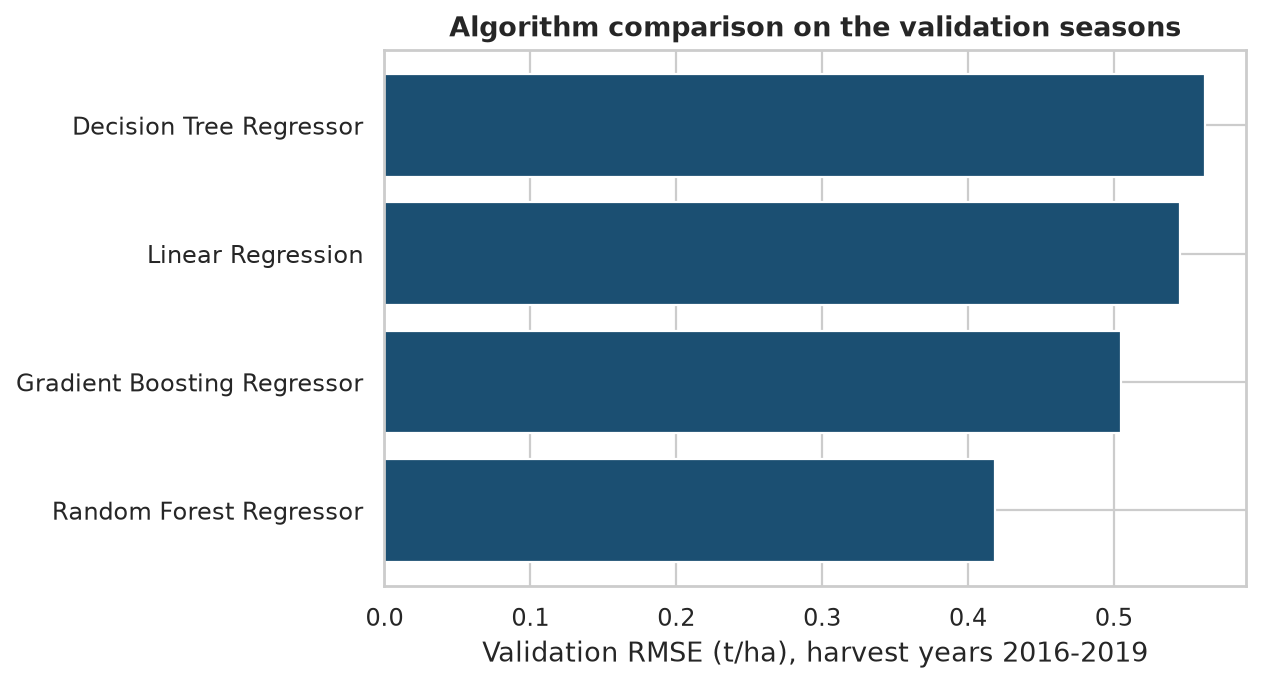

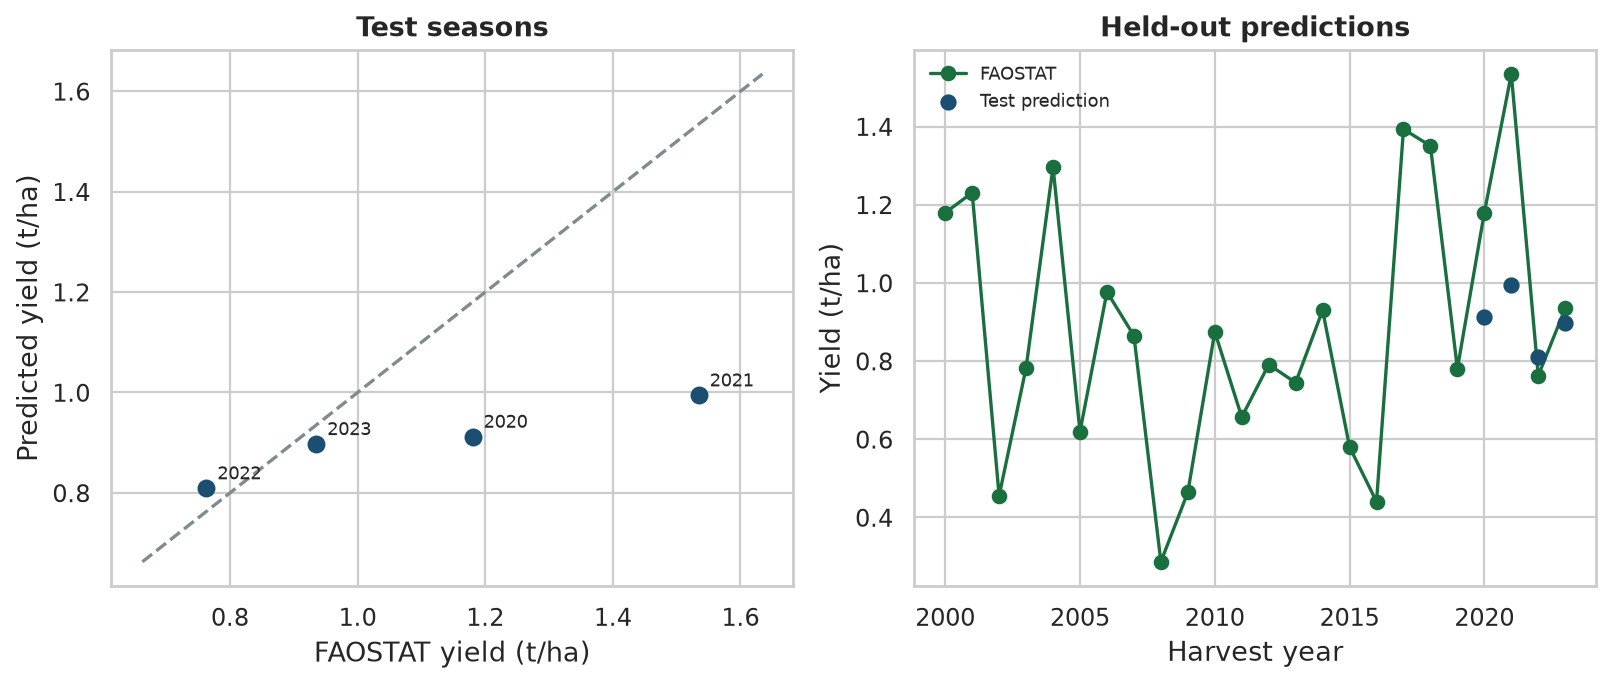

,year,yield_t_ha,predicted_t_ha,residual_t_ha,absolute_error_t_ha
0,2020,1.1801,0.9121,0.2680,0.2680
1,2021,1.5344,0.9945,0.5399,0.5399
2,2022,0.7628,0.8129,-0.0501,0.0501
3,2023,0.9350,0.8974,0.0376,0.0376


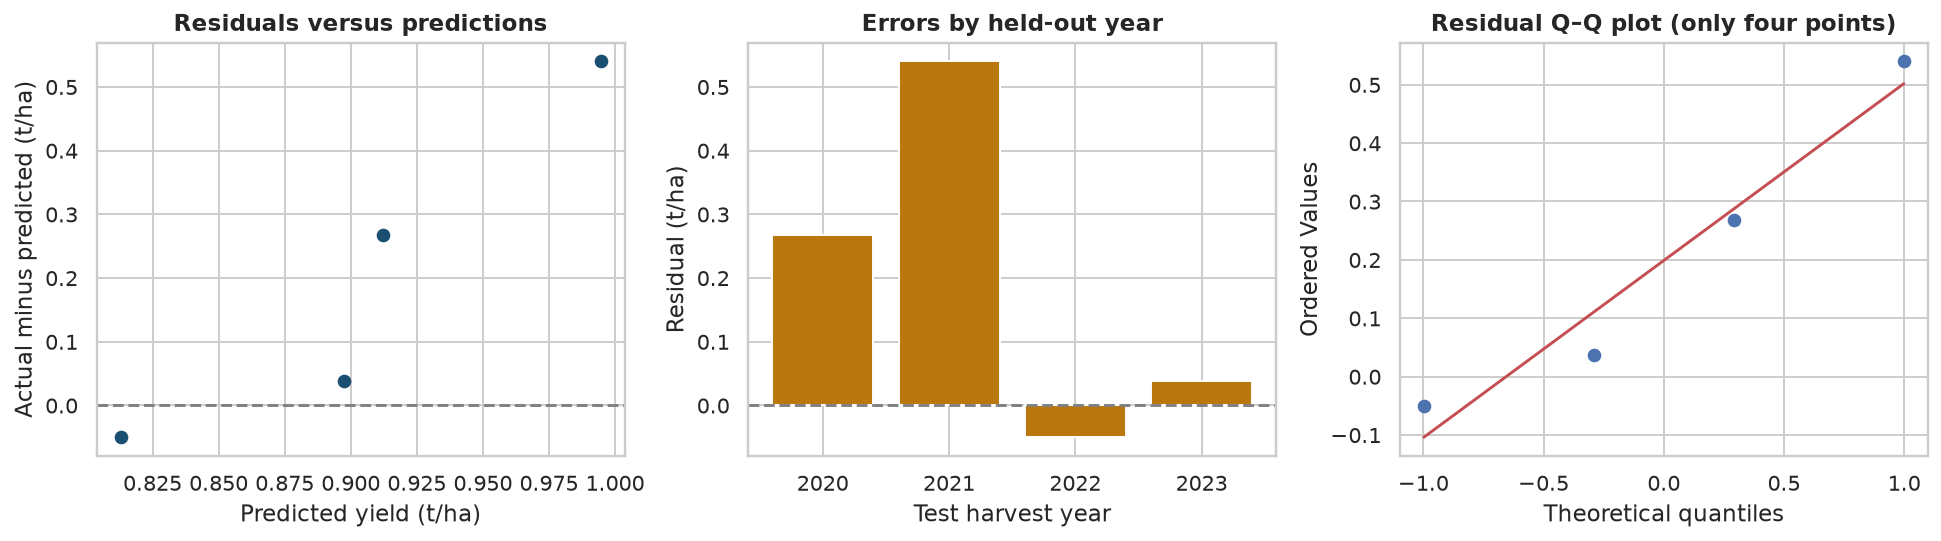

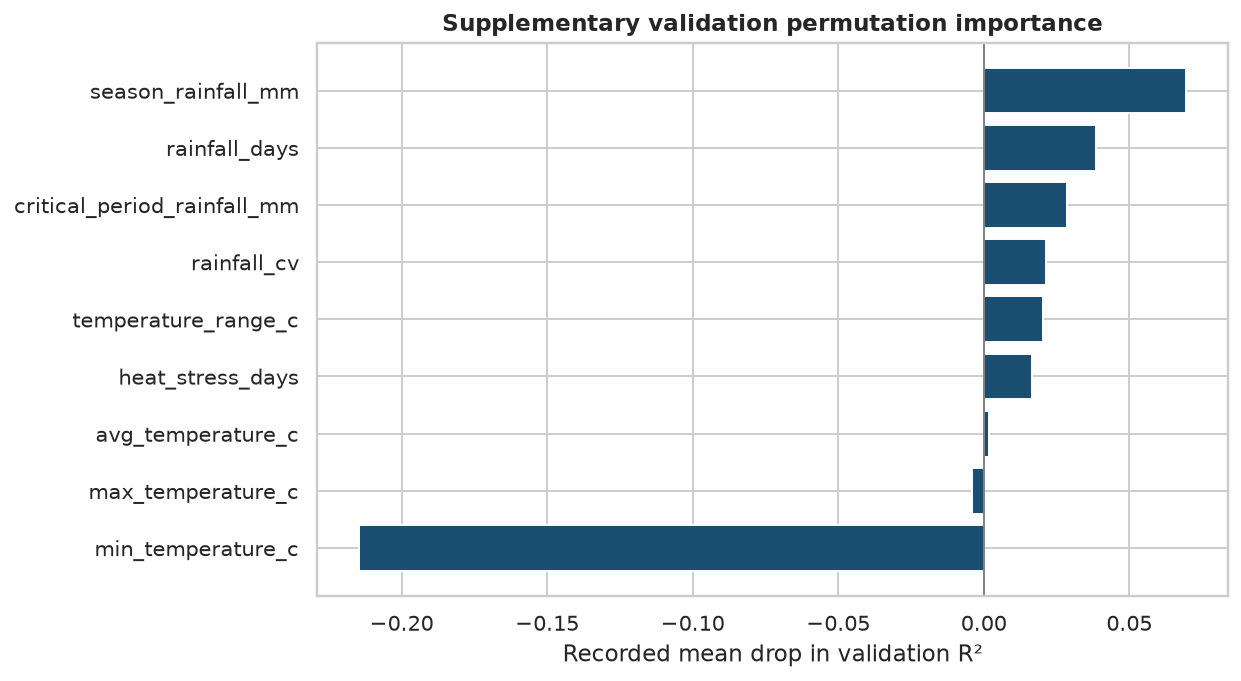

Training-only yield-band cutoffs (t/ha): [0.6568 0.8751]
Low < first cutoff; middle ≥ first and < second; high ≥ second.


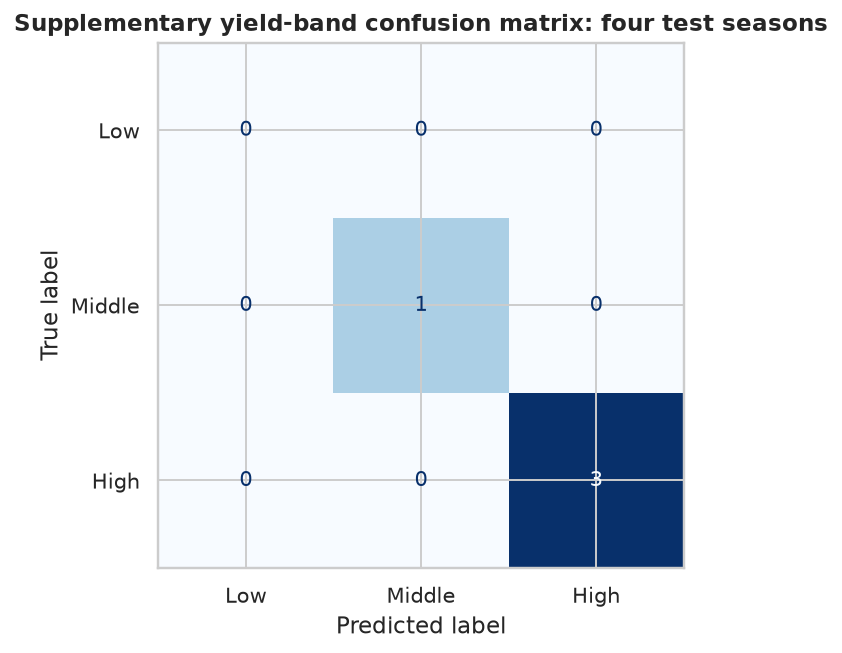

In [15]:
display(comparison)
display(expanding)
print("The grid is reported in the original tuning section above.")
print("Preserved held-out metrics:", test_scores)
display(test_frame)
for filename in ["fig_3_5_validation_rmse.png", "fig_3_6_test_predictions.png"]:
    display(NotebookImage(filename=str(FIG / filename)))
residual_frame = test_frame.copy()
residual_frame["residual_t_ha"] = residual_frame["yield_t_ha"] - residual_frame["predicted_t_ha"]
residual_frame["absolute_error_t_ha"] = residual_frame["residual_t_ha"].abs()
display(residual_frame)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].scatter(test_pred, residual_frame["residual_t_ha"], color=NAVY)
axes[0].axhline(0, color="grey", linestyle="--")
axes[0].set(xlabel="Predicted yield (t/ha)", ylabel="Actual minus predicted (t/ha)", title="Residuals versus predictions")
axes[1].bar(residual_frame["year"].astype(str), residual_frame["residual_t_ha"], color=EARTH)
axes[1].axhline(0, color="grey", linestyle="--")
axes[1].set(xlabel="Test harvest year", ylabel="Residual (t/ha)", title="Errors by held-out year")
stats.probplot(residual_frame["residual_t_ha"], dist="norm", plot=axes[2])
axes[2].set_title("Residual Q–Q plot (only four points)")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(9, 5))
importance_plot = importance_table.sort_values("importance_mean")
ax.barh(importance_plot["feature"], importance_plot["importance_mean"], color=NAVY)
ax.axvline(0, color="grey", linewidth=1)
ax.set(xlabel="Recorded mean drop in validation R²",
       title="Supplementary validation permutation importance")
plt.tight_layout(); plt.show()
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cutoffs = y.loc[train].quantile([1/3, 2/3]).to_numpy()
actual_bands = np.digitize(y.loc[test].to_numpy(), cutoffs)
predicted_bands = np.digitize(test_pred, cutoffs)
print("Training-only yield-band cutoffs (t/ha):", cutoffs)
print("Low < first cutoff; middle ≥ first and < second; high ≥ second.")
cm = confusion_matrix(actual_bands, predicted_bands, labels=[0, 1, 2])
ConfusionMatrixDisplay(cm, display_labels=["Low", "Middle", "High"]).plot(cmap="Blues", colorbar=False)
plt.title("Supplementary yield-band confusion matrix: four test seasons")
plt.tight_layout(); plt.show()


### Interpretation

Read error magnitudes in tonnes per hectare and R² against the held-out mean baseline. A negative test R² means the model did not beat a predictor using the test-target mean in the R² denominator, even if it beats the separately fitted training-mean baseline in MAE or RMSE. Permutation importance uses validation data and can be negative; correlated predictors make individual rankings unstable. Yield-band counts are sensitive to the training tertiles and the very small test sample. Neither these diagnostics nor the national target establish farm-level prediction performance.

## Appendix A Original document code and graph screenshots

These images are copied byte for byte from the supplied document and embedded as notebook attachments. They remain visible even when this notebook is moved. They are reference screenshots; supplementary charts above do not replace them. The university logo is omitted because it is not code or a graph.

### Original quality checks

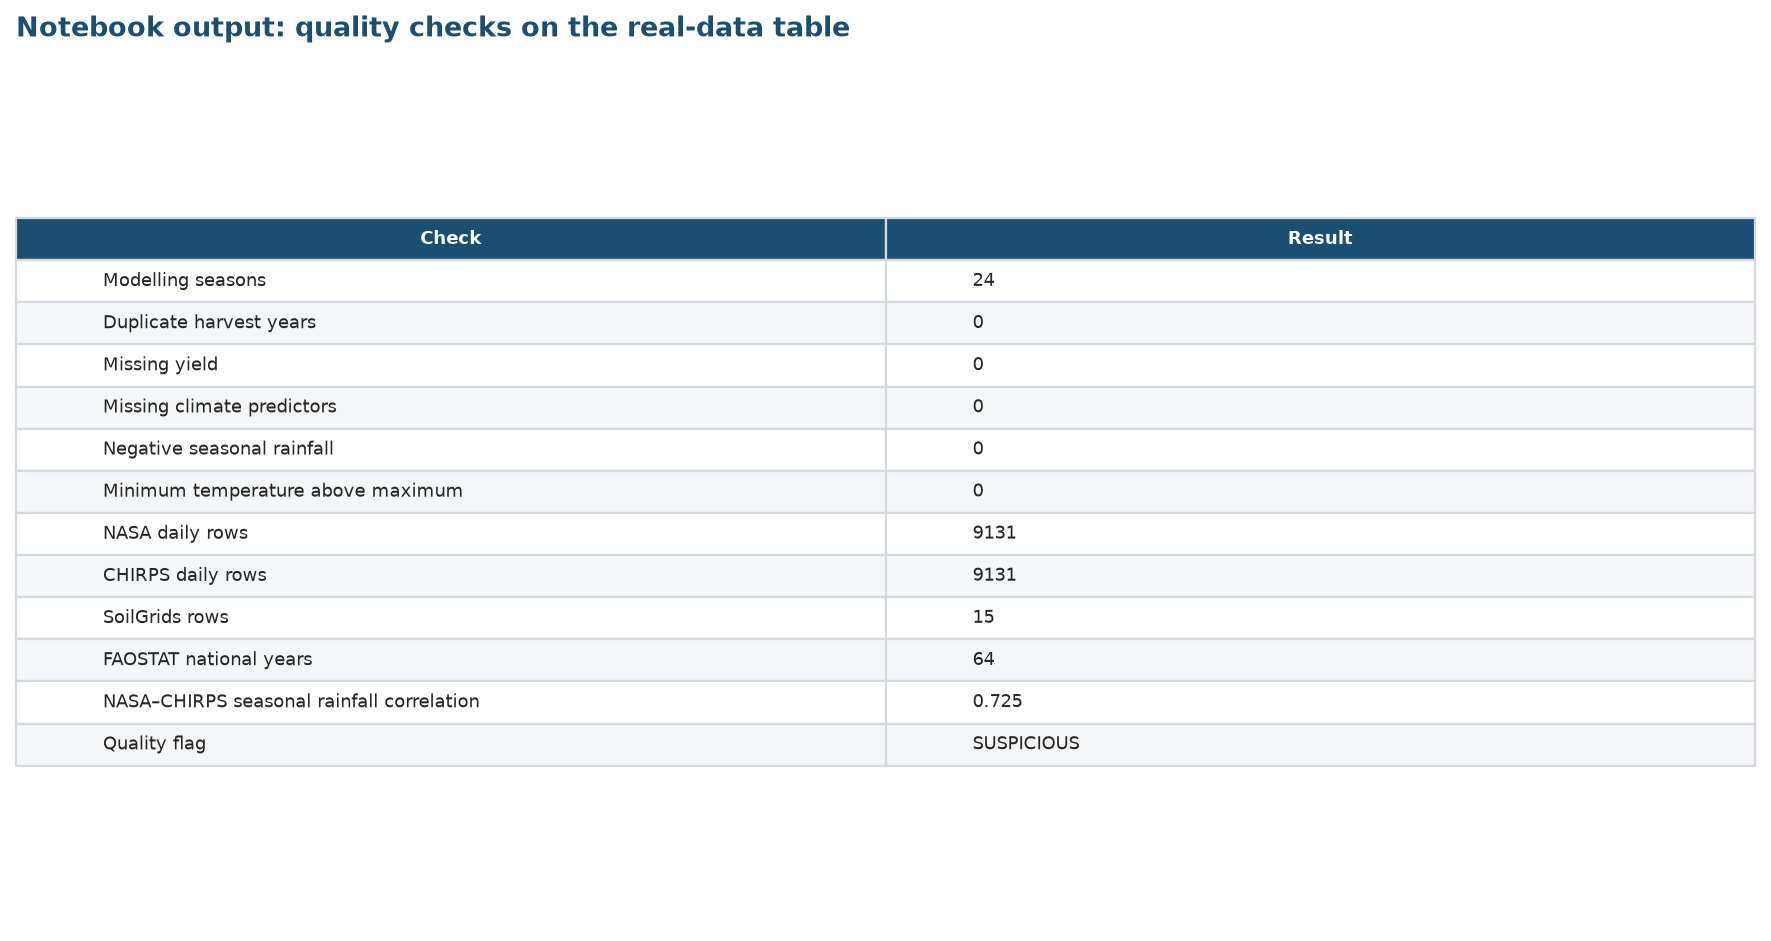

### Original rainfall agreement

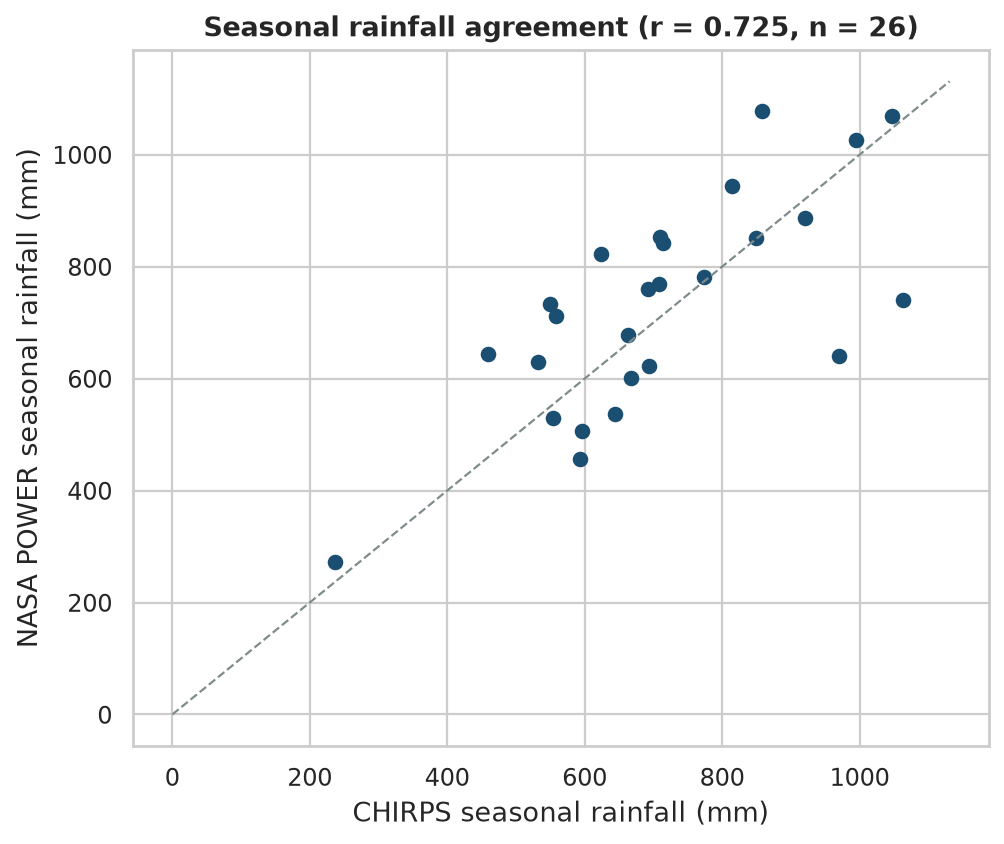

### Original held-out predictions

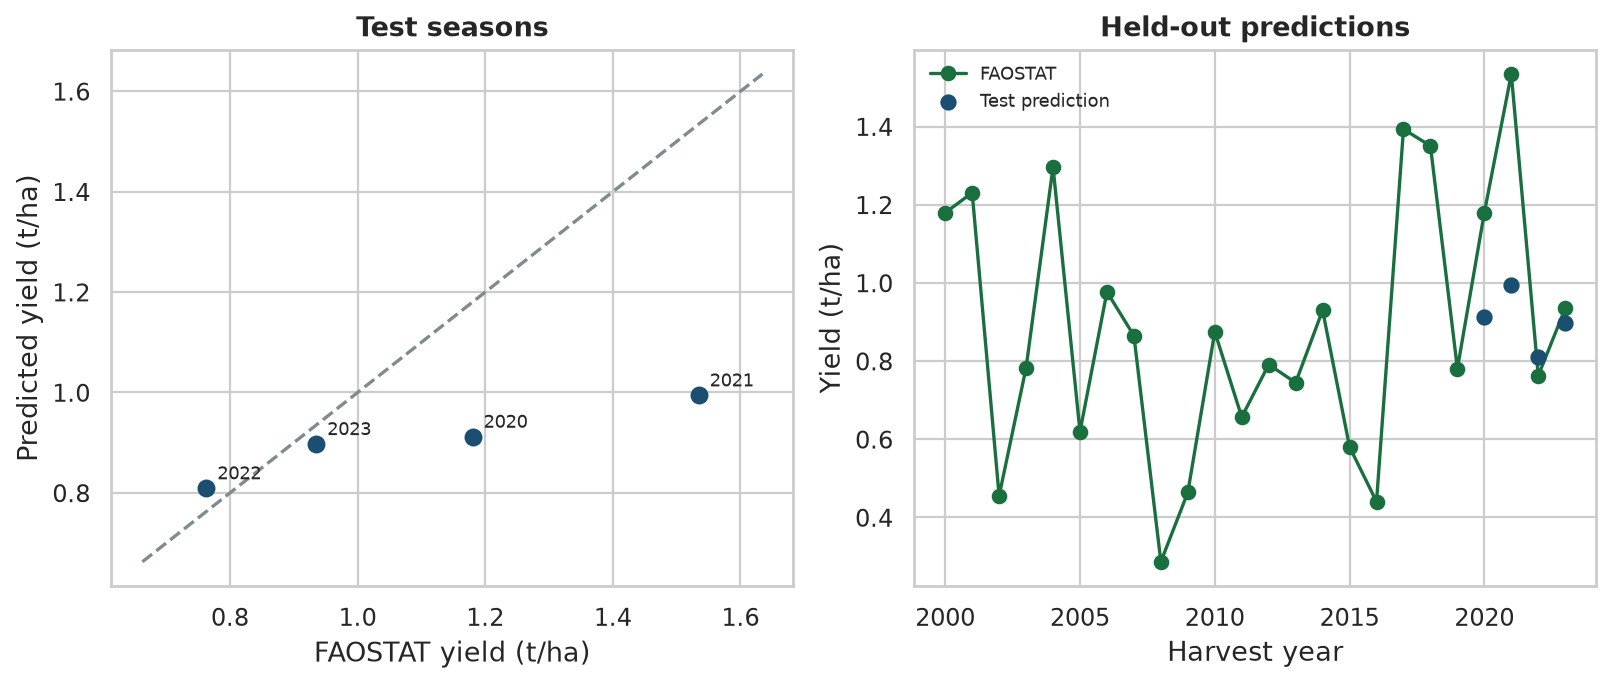

### Original yield and rainfall time series

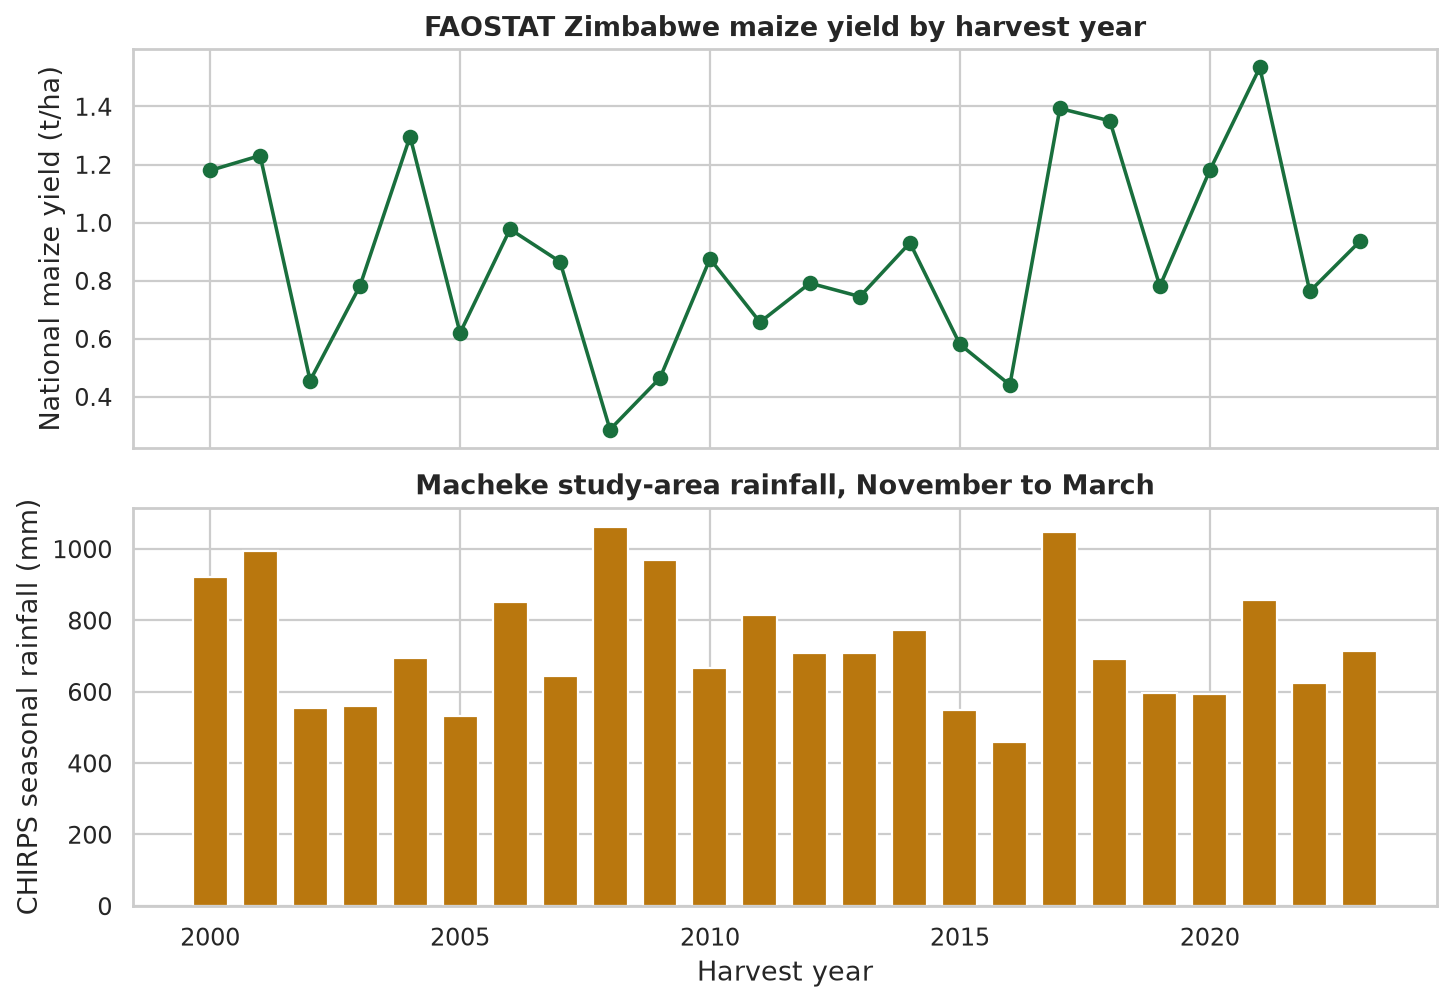

### Original correlation matrix

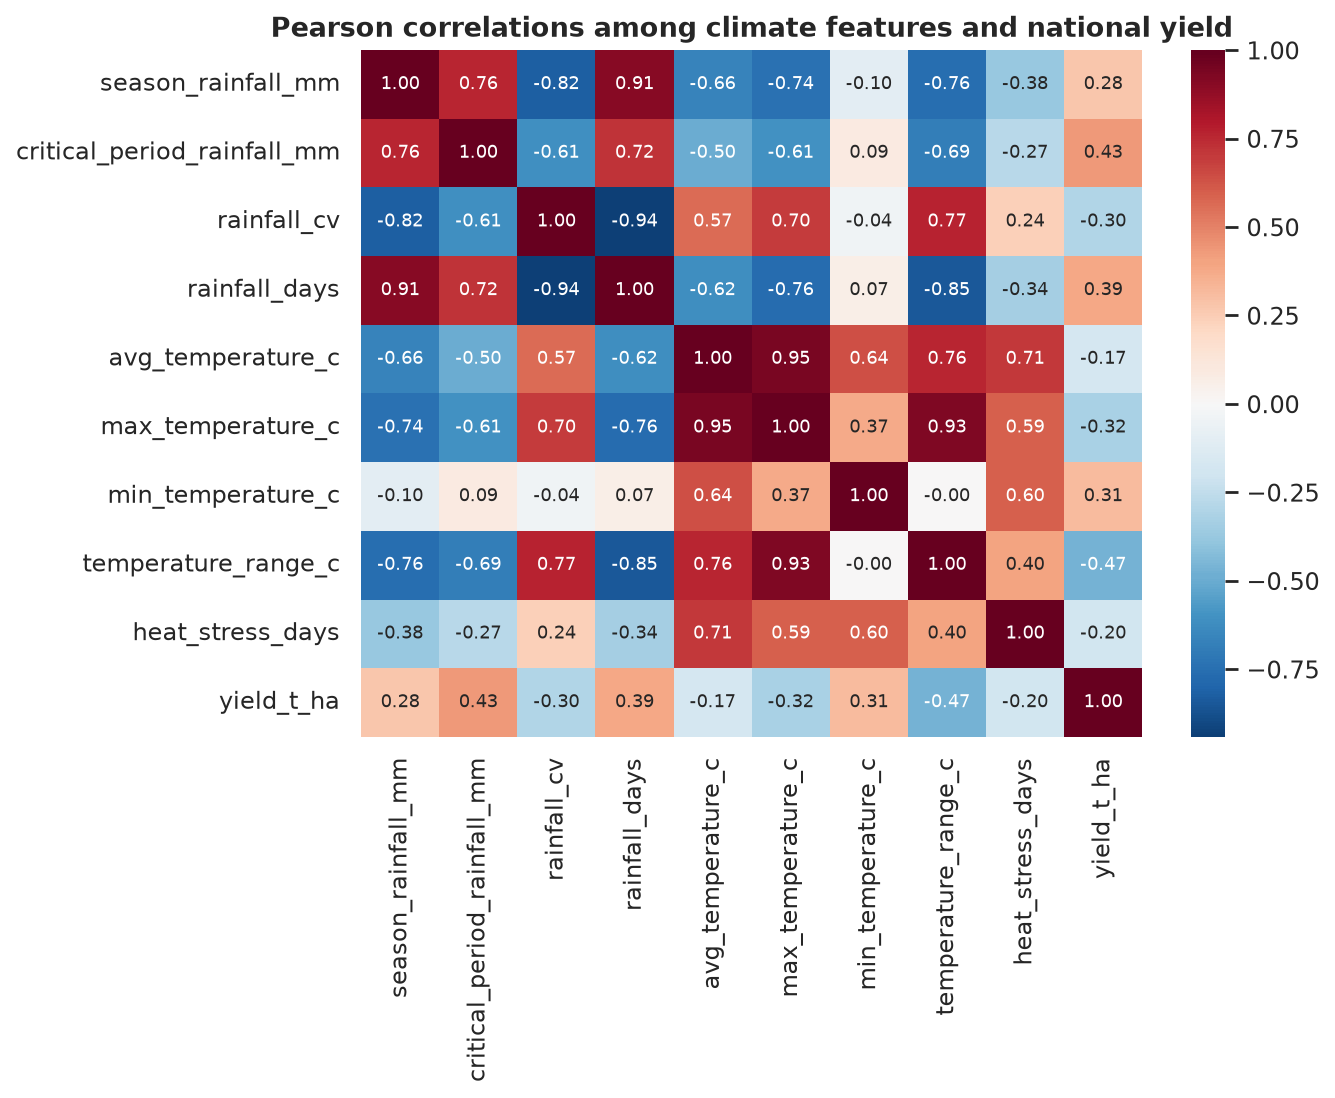

### Original yield histogram

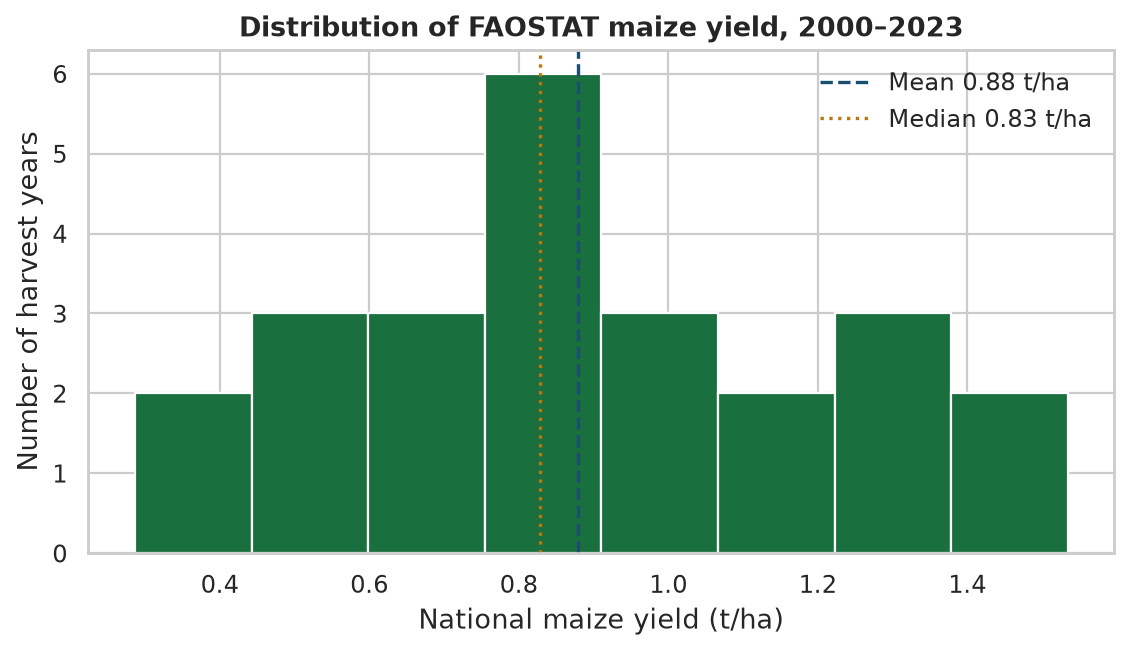

### Original rainfall and yield scatter

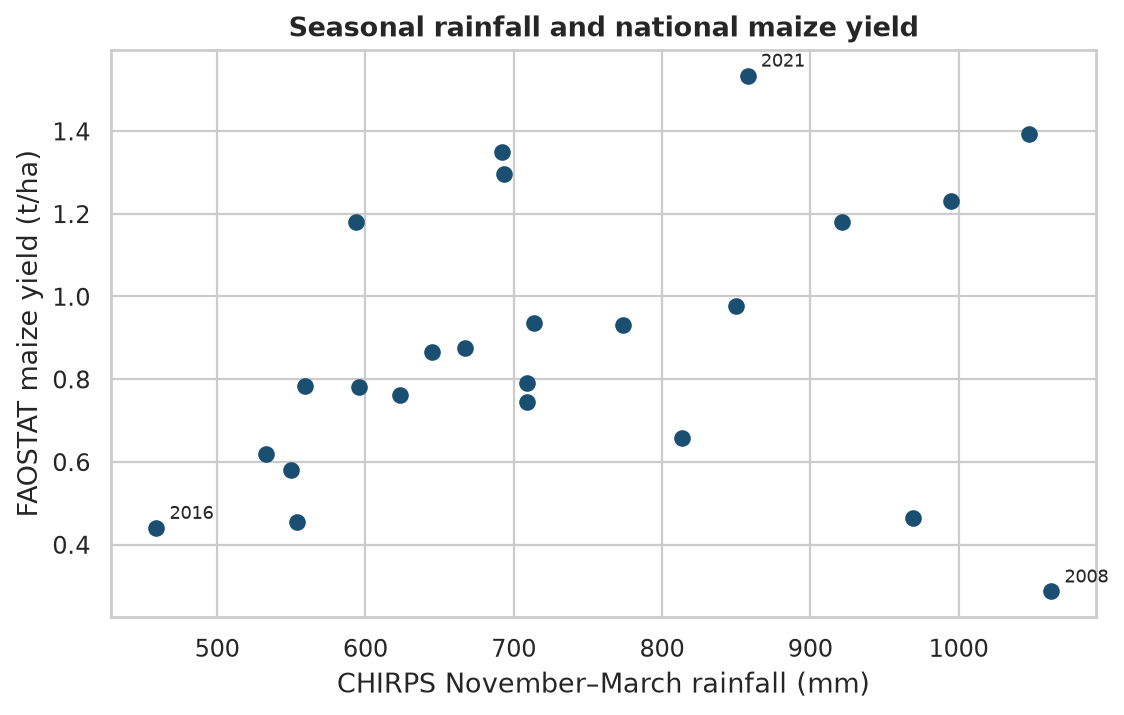

### Original validation importance

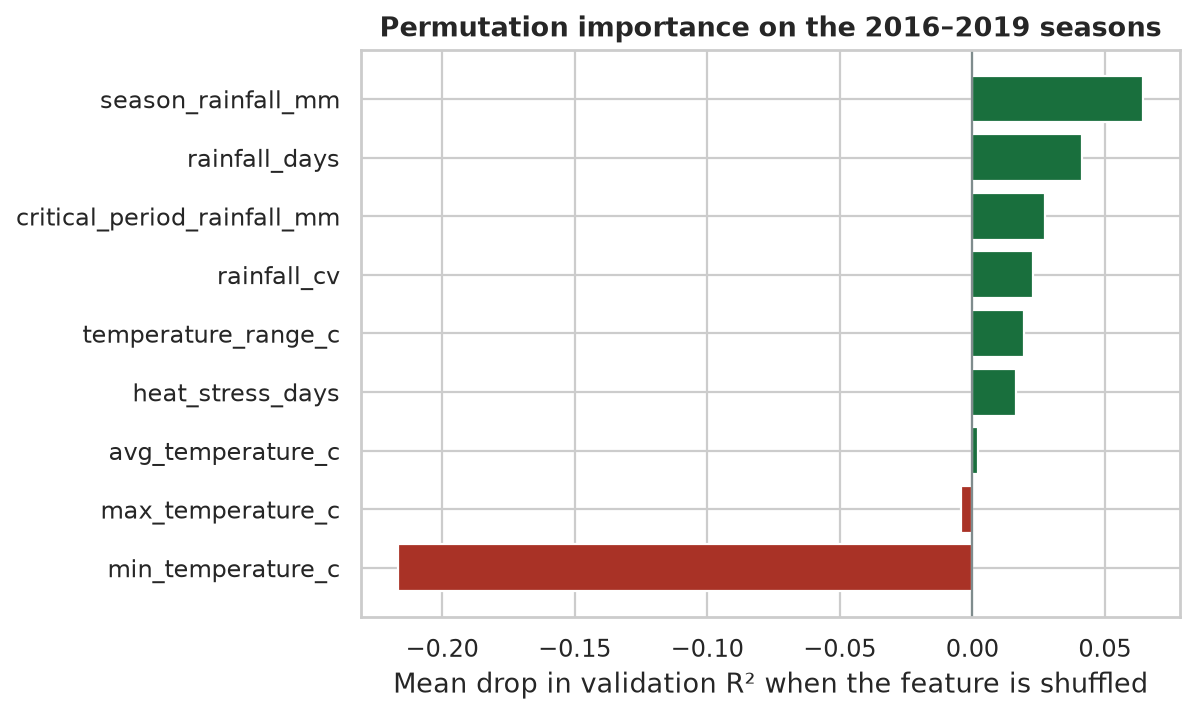

### Original acquisition code screenshot

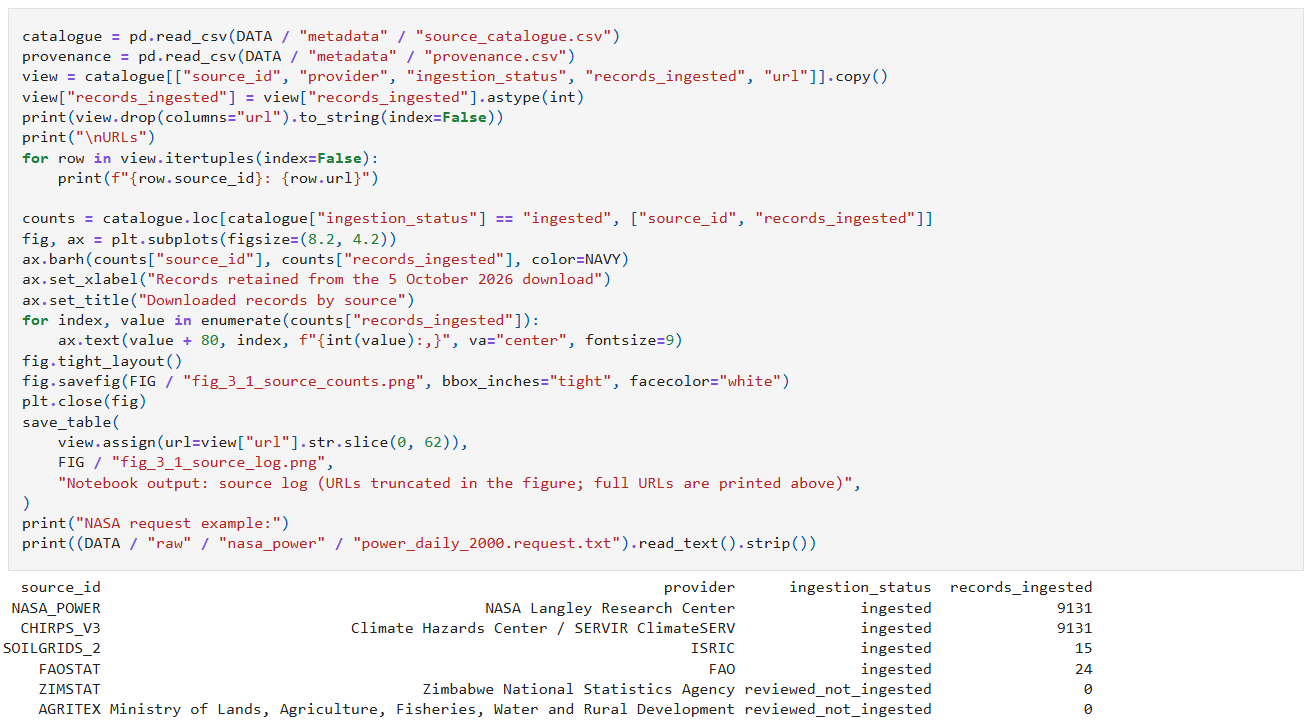

### Original quality and integration code screenshot

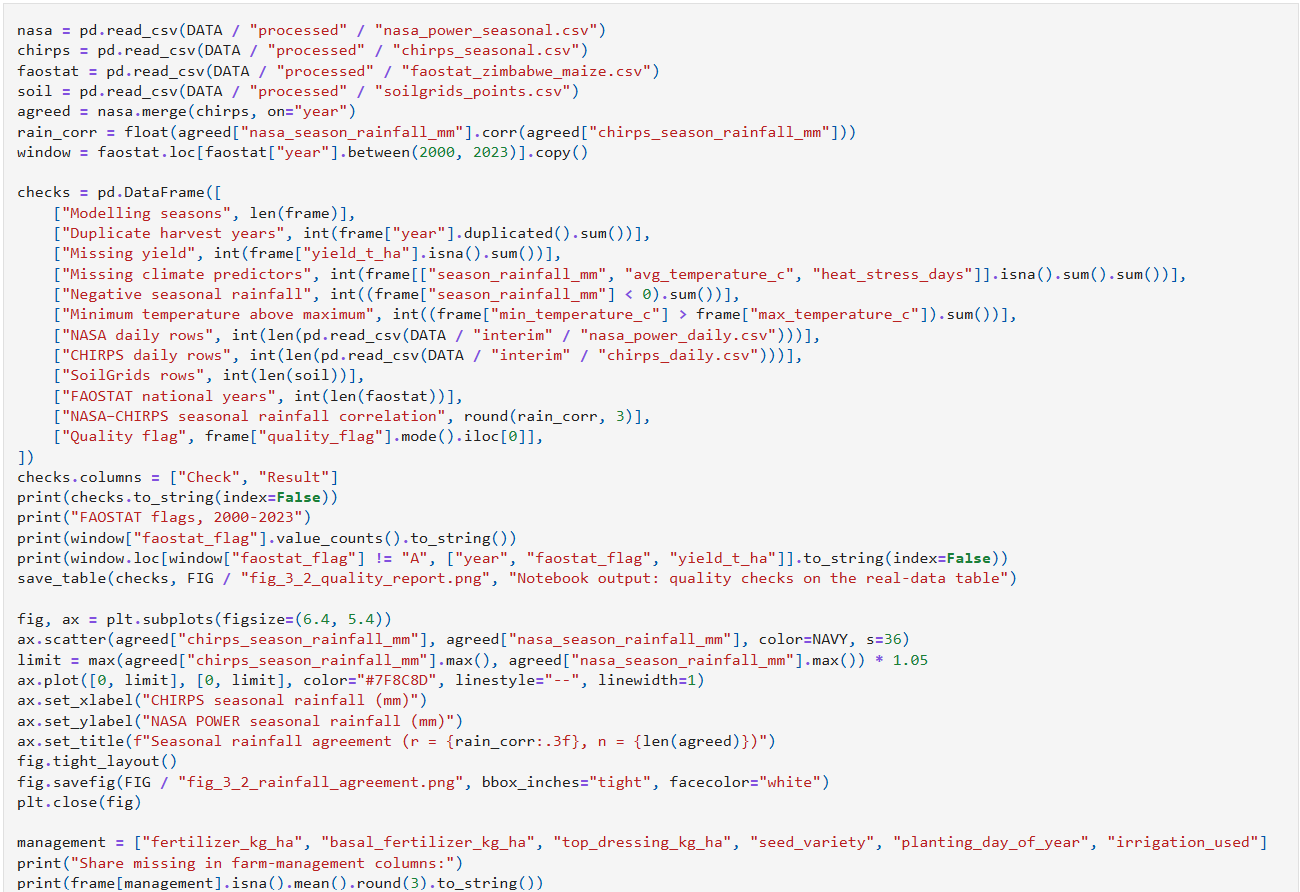

### Original model code screenshot

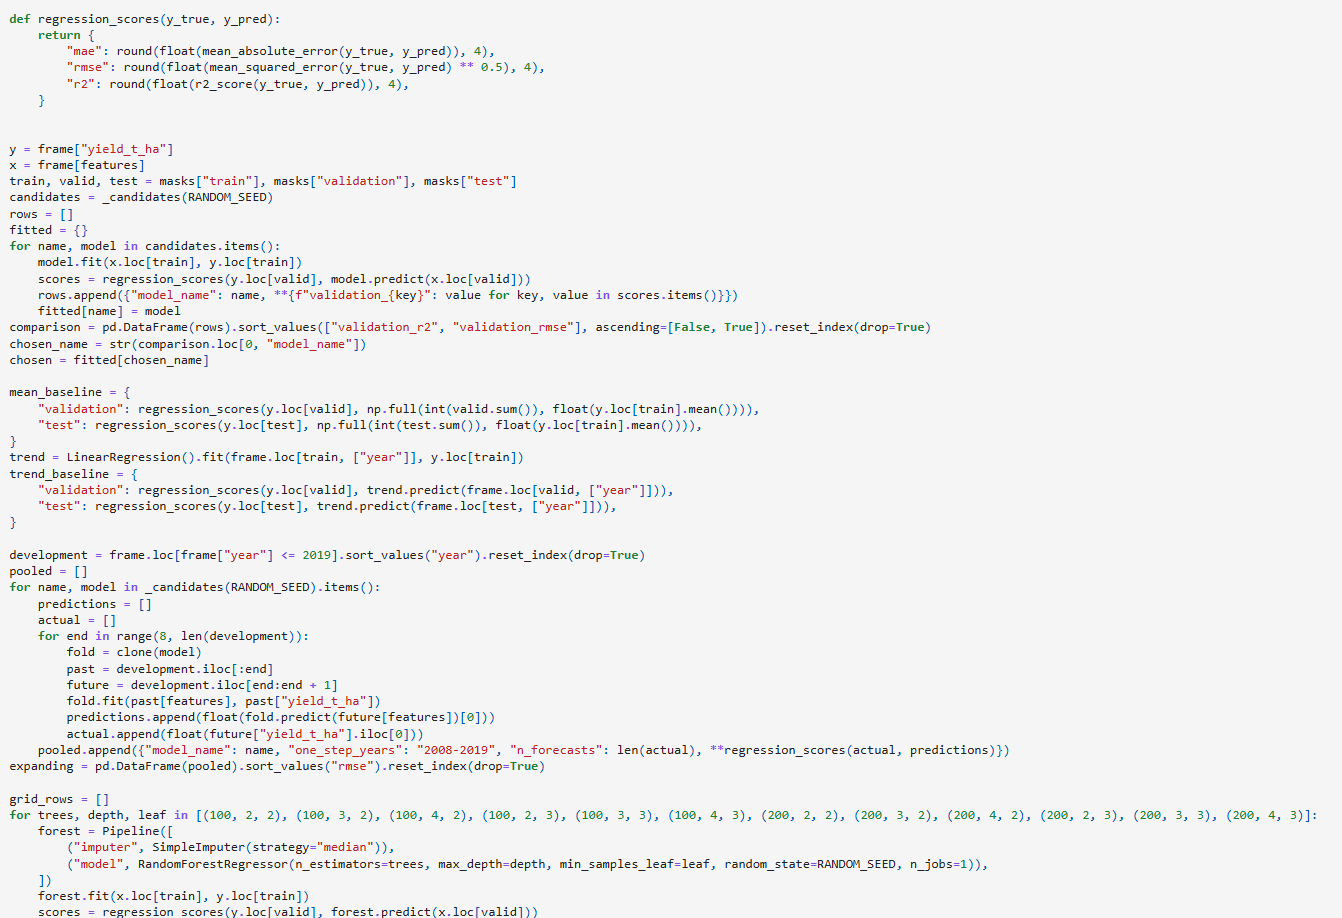

### Original evaluation code screenshot

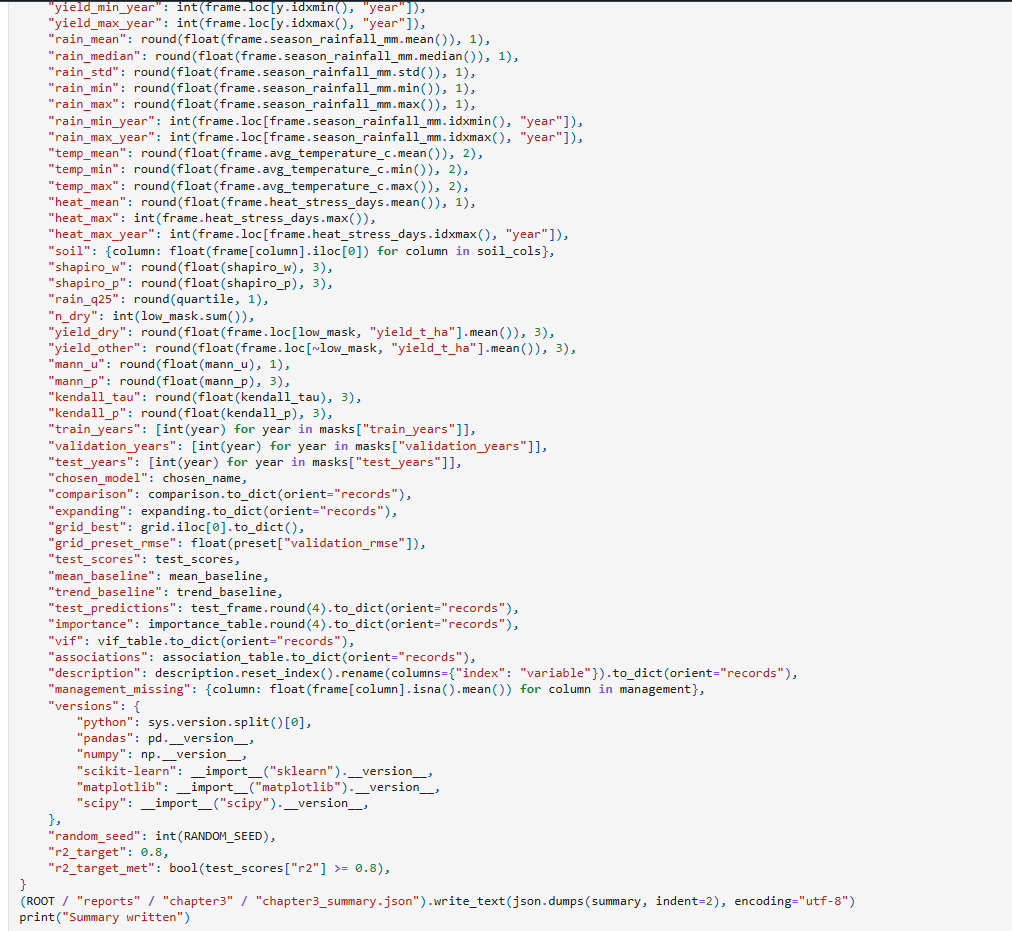

## Appendix B Consolidation provenance

Original real master code cells were copied without edits. The five numbered real-data notebooks cover the same stages and are retained alongside this notebook. Synthetic notebooks were excluded. Original code/graph screenshot hashes:

- `image2.png`: `ac1b12d748cc8f79ef9dd4444290bbe56cd285713166305db7db16ea9fd7f65b`
- `image3.png`: `1186a45489239fa90ad76b6d72f12d36b2b47fc6d62190598f804514928b8c14`
- `image4.png`: `d54fb203c79f8fad18a0d58ca632d62eb4de57cf75f45d8ca699cb3e0c5751f7`
- `image5.png`: `ca7091edc0b27257740dbfde4d952633d7a00d9585dfe05276351fdcf585f885`
- `image6.png`: `e140f626e734238dcaeb1327d347d1725ecdf25f2d0fca82d36b77161da6b95c`
- `image7.png`: `7a8d9cb5ba4b2a0c626d98837afbb5516e7abf323695a6a2fdceafac7ee77d2e`
- `image8.png`: `0b1abae1a859502f845da7e91d50f644ac6bea534173133b7b609c6a9b3834ea`
- `image9.png`: `84aa04dfec1e8c74d9987da9664f28af0abb5bd0da2f8227dbda4f5cb0243970`
- `image10.png`: `e84348041edbc2c9fc1b8b28e1d9c0ed2d05b7c13ae6bfcd5b3f8bfcf0c18dad`
- `image11.png`: `4b21392e3f970e040fdf2b24ca2098c1b9aa354079bd6bcda6507a17b39edfa8`
- `image12.png`: `f2388401f22a3ee787fd4a38846541f780799a4860ccf7074190baa687a3dd48`
- `image13.png`: `105c7bc9fc894f0597ebd9363744de432921da56bfb65185af99bb6e18931be8`